# ProEm: one programmable chip to emulate protocols with certainty
### From instruction bytes to pin waveforms on an open-source 130 nm ASIC

| | |
|---|---|
| **Team** | Paul Vincent Bezzina, Jeffrey Chan, Junzhe Chen |
| **Licence** | Apache-2.0 |
| **Target** | IHP SG13CMOS5L 130 nm through Tiny Tapeout (6 × 4 tiles, 50 MHz) |

## Can you trust your tester?

Every test has two sides: the **device under test** (DUT) and the **tester** on the other end of the
wire, which sends the DUT messages and checks its answers. A PASS means that both did their job, yet
usually only the DUT is checked. If the tester puts a bit on the line at the wrong moment, the DUT reads
it wrong, and the test blames the DUT.

The cheapest tester is a program that toggles a pin, known as *bit-banging*. Below is one: a UART
transmitter in Python, written the way bit-banging firmware is written. It waits until each bit's
deadline, then sets the pin. There is no real pin here; instead, the program records the moment at which
each bit would have been set, read from this computer's clock. A perfect UART receiver, standing in for
the DUT, then decodes the recorded waveform.

The pin and the receiver are models, but the timing is **measured, not simulated**: it is the timing of
the machine running this notebook, so the numbers change from run to run. These cells need nothing but
Python and matplotlib.

In [1]:
import bisect, random, threading, time

TEST_BAUD = 115200                 # the most common UART speed
BIT_NS = 1e9 / TEST_BAUD           # one bit period in nanoseconds

def bitbang_uart(data, baud, gap_bits=2):
    # A software UART transmitter: busy-wait until each bit's deadline, then "set the pin".
    # Returns the pin changes (time in ns, level), how late every bit came out, and when each byte started.
    T = 1e9 / baud
    changes, late, starts = [], [], []
    t0 = time.perf_counter_ns() + 20_000
    changes.append((t0 - 2 * T, 1))                  # the line idles high
    for byte in data:
        for k, bit in enumerate([0] + [byte >> i & 1 for i in range(8)] + [1]):
            deadline = t0 + k * T
            while time.perf_counter_ns() < deadline:
                pass
            now = time.perf_counter_ns()
            changes.append((now, bit))
            late.append(now - deadline)
            if k == 0:
                starts.append(now)
        t0 = max(t0 + (10 + gap_bits) * T, time.perf_counter_ns())  # two idle bits, then the next byte
    return changes, late, starts

def uart_receive(changes, baud):
    # A perfect UART receiver (the DUT): find a falling edge, sample each bit in its middle.
    # Returns {start time: byte}, with None for a frame whose stop bit is missing.
    T = 1e9 / baud
    times = [c[0] for c in changes]
    level = lambda t: changes[max(bisect.bisect_right(times, t) - 1, 0)][1]
    frames, i = {}, 1
    while i < len(changes):
        if not (changes[i][1] == 0 and changes[i - 1][1] == 1):
            i += 1
            continue
        e = changes[i][0]
        bits = [level(e + (k + 0.5) * T) for k in range(10)]
        frames[e] = sum(b << k for k, b in enumerate(bits[1:9])) if bits[9] else None
        i = bisect.bisect_right(times, e + 9.5 * T)
    return frames

def software_test(data, baud, busy=False):
    # Send `data` with the bit-banging tester, optionally while a second thread keeps the CPU busy
    stop = threading.Event()
    def other_work():
        x = 0
        while not stop.is_set():
            x += 1
    if busy:
        threading.Thread(target=other_work, daemon=True).start()
    changes, late, starts = bitbang_uart(data, baud)
    stop.set()
    frames = uart_receive(changes, baud)
    correct = sum(frames.get(s) == d for s, d in zip(starts, data))
    return {"late": late, "correct": correct}

We send 1,000 random bytes at 115200 baud three times: twice on a quiet machine, and once while a second
thread does unrelated work, as a GUI, a log writer or a USB driver would on a real host.

In [2]:
rng = random.Random(2027)
payload = bytes(rng.randrange(256) for _ in range(1000))

runs = {"quiet, run 1": software_test(payload, TEST_BAUD),
        "quiet, run 2": software_test(payload, TEST_BAUD),
        "busy CPU":     software_test(payload, TEST_BAUD, busy=True)}

print(f"{'':14}{'bits late by > 1/2 bit':>24}{'worst delay':>14}{'bytes the DUT got right':>26}")
for name, r in runs.items():
    wrong_time = sum(l > BIT_NS / 2 for l in r["late"])
    print(f"{name:14}{wrong_time:>24}{max(r['late']) / 1000:>11.1f} us"
          f"{r['correct']:>18} / {len(payload)}")
print("\nThe tester itself reported no errors in any run.")

                bits late by > 1/2 bit   worst delay   bytes the DUT got right
quiet, run 1                       188     1078.7 us               933 / 1000
quiet, run 2                       120      227.1 us               939 / 1000
busy CPU                           143    18692.1 us               954 / 1000

The tester itself reported no errors in any run.


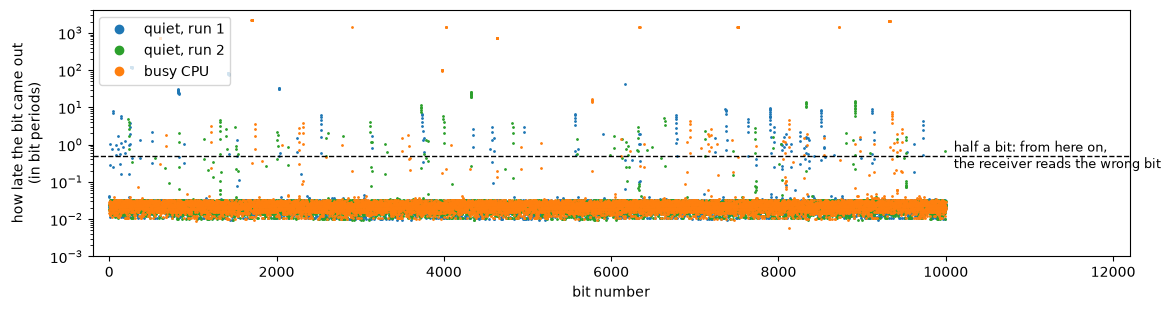

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3.2))
for (name, r), colour in zip(runs.items(), ["tab:blue", "tab:green", "tab:orange"]):
    ax.plot([l / BIT_NS for l in r["late"]], ".", markersize=2, color=colour, label=name)
ax.axhline(0.5, color="black", linewidth=1, linestyle="--")
ax.text(len(payload) * 10, 0.5, "  half a bit: from here on,\n  the receiver reads the wrong bit",
        va="center", fontsize=9)
ax.set_xlim(-200, len(payload) * 10 * 1.22)
ax.set_yscale("log")
ax.set_ylim(1e-3, None)
ax.set_xlabel("bit number")
ax.set_ylabel("how late the bit came out\n(in bit periods)")
ax.legend(loc="upper left", markerscale=6)
plt.tight_layout()
plt.show()

Three things go wrong, and none of them is the DUT's fault:

1. **The failures belong to the tester.** The receiver is perfect, yet some bytes arrive wrong. A real
   test would report them as bugs in the DUT, and someone would go looking for a problem that is not there.
2. **The result changes from run to run.** The same bytes give a different number of failures each
   time. A test like this is *flaky*: a pass means little, and a failure cannot be reproduced.
3. **The tester cannot tell.** It believes it sent every bit on time; only the clock shows that it
   did not.

Most bits leave on time, to within a few hundred nanoseconds. The trouble is the rare ones: the operating
system or another thread takes the CPU away for tens of microseconds, or, in the busy run, for several
milliseconds (Python lets the other thread run for 5 ms at a time). Python is a worst case. Firmware in C
on a microcontroller is far tighter, but an interrupt that arrives in the middle of a byte delays it in
the same way, only for less time.

The cure is to take timing away from software: let hardware that counts clock cycles decide when each
bit goes out. That is what ProEm does, and section 2.3 checks it on the chip's RTL.

**ProEm** is a programmable protocol emulator. A host (an RP2040 or a PC) describes one frame of a serial
protocol in a few instruction bytes, and the chip runs it in hardware with clock-exact timing: UART, SPI,
I²C, CAN, USB low speed, 10BASE-T receive and about twenty more standards, all from one instruction set.

This notebook follows those bytes all the way down:

1. **The instruction set:** how a stream of bytes becomes instructions, with UART, SPI and I²C examples.
2. **The RTL:** the same bytes are fed to the chip's SystemVerilog, simulated with Yosys CXXRTL, and the
   waveform on the pin is decoded back into data. Section 2.3 answers the tester problem above, and
   section 2.4 opens up the chip to show how.
3. **Verification:** margins, a formal proof, random programs, and what the checks found.
4. **Silicon:** synthesis of one module, the finished layout and its numbers.
5. **Limitations** and future work.

## Why a protocol emulator chip?

Chips talk to each other over serial protocols: sensors over I²C, flash and displays over SPI, GPS modules
over UART, car electronics over CAN. To **test** a device, or to **stand in** for one, you need something
that speaks its protocol with the right timing. The usual options each have a cost:

| Approach | Drawback |
|---|---|
| One dedicated peripheral per protocol | A different part for every protocol; fixed features |
| Bit-banging from a microcontroller | The CPU toggles pins in software, so timing depends on what else the CPU is doing (see above); speed is limited; every protocol is new firmware |
| An FPGA | Flexible, but each protocol is new hardware description, and the board costs more and draws more power |

ProEm takes a middle path: **fixed hardware that is programmed with data**. The host describes one frame
of the protocol in a few instruction bytes; the chip then sends and receives it with timing exact to its
50 MHz clock, reacts on chip where the protocol needs an immediate answer (acknowledges, arbitration,
CRC checks), and reports what happened. Changing protocol means sending different bytes, not new
firmware or new hardware.

ProEm was designed for UART, SPI and I²C, with low-speed USB and 10 Mbit Ethernet as stretch goals,
for Tiny Tapeout's IHP 130 nm shuttle.

| | |
|---|---|
| Channels | 2 independent channels, running at the same time |
| Verified standards | UART, SPI (controller and target, all four modes), I²C (controller and target), USB low speed, 10BASE-T receive, CAN, PS/2 and about twenty more |
| On-chip decisions | `BRANCH` rules, any CRC of 1 to 16 bits, fixed replies such as the USB ACK |
| Silicon | IHP SG13CMOS5L 130 nm, 6 × 4 Tiny Tapeout tiles, timing met at 50 MHz at every corner |

## Chip Overview

![architecture](https://raw.githubusercontent.com/Vertrex-star/ProEm-Open-Source-Protocol-Emulator/main/docs/images/protocol_emulator_architecture.png)

The host sends instruction bytes over a UART, and the **control unit** decodes them into configuration
registers. Two identical channels, A and B, each run frames on the pins. Received data and one status byte
per frame go back to the host on a second UART. Section 2.4 opens up a channel, once you have seen it run.

Each group of instructions in section 1 configures one part of this picture:

| Instructions | Hardware they set up |
|---|---|
| `START`, `HDR`, `MAIN`, `END`, `WDOG`, `ORDER` | The frame chain's blocks |
| `LINE`, `CLOCK`, `OUT` | The line codec |
| `BRANCH` | The branch unit, the CRC unit and the reply |
| `DATA`, `RUN`, `HALT`, `CLEAR` | The host FIFO and the chain's control |
| `LINK` | The return path's bit rate |

## 0. Setup

Everything is installed with `pip`, as the Code-a-Chip FAQ asks. The simulation uses
[YoWASP Yosys](https://yowasp.org) (Yosys compiled to WebAssembly) and the system C++ compiler, which
Colab already has.

### 0.1 Tool versions

| Tool | Tested version | Used for |
|---|---|---|
| Python | 3.12 | everything |
| [YoWASP Yosys](https://yowasp.org) (`yowasp-yosys`) | 0.70.0.0.post1259 (Yosys 0.70) | RTL → C++ model (CXXRTL), synthesis, SymbiYosys |
| [Z3](https://github.com/Z3Prover/z3) (`z3-solver`) | 5.3.2.0 | the bounded proof in section 3.2 |
| `matplotlib` | 3.11 | plots |
| g++ | 13.3 | compiling the simulation model |

In [4]:
%pip install -q --disable-pip-version-check yowasp-yosys==0.70.0.0.post1259 matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
import os, subprocess, sys, time

# The ProEm repository. It must be public for this notebook to run on Colab.
REPO_URL = "https://github.com/Vertrex-star/ProEm-Open-Source-Protocol-Emulator.git"

# Run from a local checkout (the notebook sits in its notebook/ folder) if there is one;
# PROEM_DIR overrides this, and otherwise, as on Colab, the repository is cloned into ./proem.
local = os.path.abspath(os.pardir)
if "PROEM_DIR" not in os.environ and os.path.isdir(os.path.join(local, "host")):
    os.environ["PROEM_DIR"] = local
REPO_DIR = os.path.abspath(os.environ.get("PROEM_DIR", "proem"))

if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)

sys.path.insert(0, os.path.join(REPO_DIR, "host"))
import proem_host as ph      # builds instruction bytes from arguments
import proem_disasm as dis   # a disassembler that turns bytes back into readable instructions

print("Using ProEm from", REPO_DIR)

Using ProEm from /Users/jeffery/Programming/ISSCC2027-code-a-chip


## 1. The instruction set

### 1.1 Every protocol frame is a chain of fields

Serial protocols look very different on the wire, but almost all of their frames have the same shape:
something that marks the beginning, a few fixed fields such as an address or a command, the data
itself, and sometimes a condition that marks the end.

| Protocol | Beginning | Fixed fields | Data | End |
|---|---|---|---|---|
| UART | start bit `0` | — | 8 data bits + stop bit `1` | — |
| I²C write | START condition | address + W, ACK, register, ACK | data bytes, each followed by an ACK | STOP condition |
| SPI | chip select goes low | — | bits clocked out on SCK | chip select goes high |
| CAN | start of frame | identifier, control field | data + CRC-15 | ACK slot |

ProEm builds this shape in hardware. Each channel has a **frame chain**: a `START` block, up to six
header blocks (`HDR 1`–`HDR 6`), a `MAIN` block and an `END` block, which run strictly in order, one bit
per tick. For each block the host sets how many bits it handles, whether it **writes** (sends a value)
or **reads** (compares with, or captures, what is on the line), and which pin it uses. The difference
between two protocols is therefore a difference in *settings*, not in hardware.

The settings are sent as **instructions**. The rest of this section shows how to read them.

### 1.2 The header byte

Instructions are written in hexadecimal because one hex digit is exactly four bits, so a byte is always
two hex digits: `0x90` is `1001 0000`, `0xC7` is `1100 0111`.

Every instruction starts with a **header byte** with the same layout:

| bit | 7 6 5 4 | 3 | 2 1 0 |
|---|---|---|---|
| field | `OP` | `CH` | `N` |
| meaning | which instruction | channel A (0) or B (1) | a small parameter |

Because `OP` is the top four bits, the **first hex digit of a header byte is the opcode**. The second
hex digit holds `CH` and `N`: adding 8 to it switches the instruction from channel A to channel B
(`0x90` → `0x98`). Small parameters fit in `N` and need no extra byte: `ORDER` uses it for the bit
order, `RUN` for the run mode, and `DATA` for the entry length minus one.

In [6]:
def explain_header(b):
    # one header byte splits into "OP | CH | N"
    op, ch, n = dis.header(b)
    bits = f"{b:08b}"
    print(f"0x{b:02X} = {bits[:4]} {bits[4]} {bits[5:]}   ->  OP=0x{op:X} {dis.NAMES[op]:<6} "
          f"CH={'AB'[ch]}  N={n}   ({dis.OPERANDS[op]} operand byte(s) follow)")

for b in (0x90, 0x98, 0x60, 0x61, 0xC7, 0xC0, 0x70, 0x72):
    explain_header(b)

0x90 = 1001 0 000   ->  OP=0x9 CLEAR  CH=A  N=0   (0 operand byte(s) follow)
0x98 = 1001 1 000   ->  OP=0x9 CLEAR  CH=B  N=0   (0 operand byte(s) follow)
0x60 = 0110 0 000   ->  OP=0x6 ORDER  CH=A  N=0   (0 operand byte(s) follow)
0x61 = 0110 0 001   ->  OP=0x6 ORDER  CH=A  N=1   (0 operand byte(s) follow)
0xC7 = 1100 0 111   ->  OP=0xC DATA   CH=A  N=7   (1 operand byte(s) follow)
0xC0 = 1100 0 000   ->  OP=0xC DATA   CH=A  N=0   (1 operand byte(s) follow)
0x70 = 0111 0 000   ->  OP=0x7 RUN    CH=A  N=0   (0 operand byte(s) follow)
0x72 = 0111 0 010   ->  OP=0x7 RUN    CH=A  N=2   (0 operand byte(s) follow)


### 1.3 Instructions have different lengths

In a fixed-width instruction set (for example the 16-bit Hack computer from *nand2tetris*), every
instruction is one word and the next instruction always starts at the next word. ProEm's instructions
are **variable length**: the header byte is followed by 0 to 4 *operand bytes*, and the number depends
only on the opcode.

In [7]:
print("OP  instruction  operand bytes")
for op in range(16):
    print(f"{op:X}   {dis.NAMES[op]:<11}  {dis.OPERANDS[op]}")

OP  instruction  operand bytes
0   NOP          0
1   START        3
2   HDR          3
3   MAIN         3
4   END          4
5   WDOG         2
6   ORDER        0
7   RUN          0
8   HALT         0
9   CLEAR        0
A   LINE         2
B   CLOCK        4
C   DATA         1
D   OUT          1
E   LINK         2
F   BRANCH       3


This table is all the chip needs to find where one instruction ends and the next begins. The control
unit (`src/core/control_unit.sv`) repeats three steps:

1. Take the next byte as a header byte.
2. Look up how many operand bytes its opcode needs, and take that many.
3. The byte after them is the next header byte.

Operand bytes are never mistaken for headers, even when they look like one (`0x40`, `0x00`), because
they are consumed in order. The same rule also means that a single lost byte shifts every instruction
after it, so the host must send the bytes exactly as built.

`proem_disasm.split()` applies the same three steps in Python.

### 1.4 A complete program: send the letter `A`

`proem_host.uart_tx()` builds the program that turns channel A into a 115200-baud UART transmitter and
sends one character:

In [8]:
BAUD = 115200
program, rest = ph.uart_tx(0, BAUD, b"A")
print(len(program), "bytes:", " ".join(f"{b:02X}" for b in program))

25 bytes: 90 60 A0 00 00 B0 40 00 01 B2 D0 E0 10 81 00 00 30 40 00 09 C7 41 C0 01 70


Cut with the three steps above, the 25 bytes are 10 instructions. Each coloured group below is one
instruction, and its outlined byte is the header.

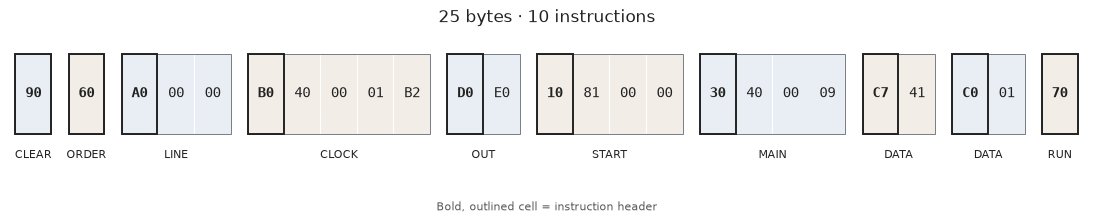

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_program(program):
    instrs = list(dis.split(program))

    fills = ("#E8EEF4", "#F2EEE7")
    text_colour = "#222222"
    border_colour = "#747D87"
    instruction_gap = 0.45
    cell_width = 0.98

    total_width = len(program) + instruction_gap * max(0, len(instrs) - 1)

    fig, ax = plt.subplots(
        figsize=(max(8, total_width * 0.38), 2.3),
        facecolor="white"
    )

    x = 0
    for k, ins in enumerate(instrs):
        op, ch, n = dis.header(ins[0])
        fill = fills[k % len(fills)]
        group_width = len(ins) - (1 - cell_width)

        # Byte cells: small internal gaps.
        for j, b in enumerate(ins):
            ax.add_patch(Rectangle(
                (x + j, 0), cell_width, 1,
                facecolor=fill, edgecolor="none"
            ))
            ax.text(
                x + j + cell_width / 2, 0.5, f"{b:02X}",
                ha="center", va="center",
                fontsize=10, fontfamily="DejaVu Sans Mono",
                fontweight="bold" if j == 0 else "normal",
                color=text_colour
            )

        # Thin outline encloses the complete instruction.
        ax.add_patch(Rectangle(
            (x, 0), group_width, 1,
            fill=False, edgecolor=border_colour, linewidth=0.7
        ))

        # Stronger outline identifies its header byte.
        ax.add_patch(Rectangle(
            (x, 0), cell_width, 1,
            fill=False, edgecolor=text_colour, linewidth=1.4
        ))

        ax.text(
            x + group_width / 2, -0.27, dis.NAMES[op],
            ha="center", va="center",
            fontsize=8, color=text_colour
        )

        x += len(ins) + instruction_gap

    ax.set_xlim(-0.15, total_width + 0.15)
    ax.set_ylim(-0.6, 1.15)
    ax.axis("off")
    ax.set_title(
        f"{len(program)} bytes · {len(instrs)} instructions",
        fontsize=12, color=text_colour, pad=14
    )

    fig.text(
        0.5, 0.06, "Bold, outlined cell = instruction header",
        ha="center", fontsize=8, color="#595959"
    )
    fig.tight_layout(rect=(0, 0.12, 1, 1))
    return fig, ax


fig, ax = plot_program(program)
# Optional vector export:
# fig.savefig("program.pdf", bbox_inches="tight")
plt.show()

The operand bytes are read field by field, with the layout given for each instruction in the ISA
reference (`docs/protocol_emulator_isa.pdf`). Take the `START` instruction, `10 81 00 00`. Its first
operand byte is `0x81`:

In [10]:
def show_fields(value, fields):
    # Print the named bit fields of one operand byte, most significant first
    print(f"0x{value:02X} = {value:08b}")
    pos = 8
    for name, width in fields:
        pos -= width
        print(f"   {name:<5} = {value >> pos & ((1 << width) - 1):0{width}b}")

show_fields(0x81, [("W", 1), ("CAP", 1), ("GRP", 2), ("CYC", 4)])

0x81 = 10000001
   W     = 1
   CAP   = 0
   GRP   = 00
   CYC   = 0001


`W = 1` makes the block write, `CYC = 1` makes it one bit long, the second operand byte selects pin 0,
and the third is the value to send, `0x00`. In words: *send a single 0 on pin 0*, which is exactly a
UART start bit. The disassembler does this for every instruction:

In [11]:
print(dis.disassemble(program))

90               CLEAR  ch=A
60               ORDER  ch=A  LSB first
A0 00 00         LINE   ch=A  code=NRZ, pin=0
B0 40 00 01 B2   CLOCK  ch=A  ASYNC div=434 (~115.2 kbit/s)
D0 E0            OUT    ch=A  push-pull always, idle=1
10 81 00 00      START  ch=A  write 1 bit, value=0x00, pin=0
30 40 00 09      MAIN   ch=A  write 9 bits, pin=0
C7 41            DATA   ch=A  8 bits, value=0x41
C0 01            DATA   ch=A  1 bit, value=0x01
70               RUN    ch=A  mode=RUN


Read from top to bottom, the program says:

| Instruction | Meaning |
|---|---|
| `CLEAR` | Start from a clean channel: forget every earlier setting. |
| `ORDER` | Send the least significant bit first, as UART requires. |
| `LINE` | Plain NRZ line coding on pin 0 (USB would use NRZI, 10BASE-T Manchester). |
| `CLOCK` | Time each bit with the internal divider: 434 clocks, 50 MHz / 434 ≈ 115200 baud. |
| `OUT` | Drive the pin push-pull, and hold it high between frames (the UART idle level). |
| `START` | Write one bit, 0: the start bit. |
| `MAIN` | Write 9 bits, taken from the host's `DATA` entries. |
| `DATA` ×2 | Queue 8 bits of `0x41` (`A`), then 1 bit of `1` (the stop bit). |
| `RUN` | Start the frame. |

Everything up to `MAIN` is set once. To send the next character, the host only sends two more `DATA`
instructions (4 bytes); in plain `RUN` mode the chip starts a new frame whenever data is waiting.

The disassembler only translates. It checks that each instruction is well formed, not that the program
makes sense: `90 C7 48 C0 01 70` disassembles cleanly into `CLEAR`, two `DATA` and `RUN`, but sends
nothing useful, because `CLEAR` has removed the line, clock, output and frame settings it would need.

### 1.5 SPI: two channels working together

SPI has a clock line (SCK) and no start bit. Here channel A is the SPI controller: it generates SCK and
chip select and writes MOSI. Channel B listens on MISO, clocked by the same SCK read back on pin 1.
These programs come from the design reference (`docs/protocol_emulator_design.pdf`).

In [12]:
spi_a = bytes.fromhex("61 A0 00 00 B0 81 00 00 06 D0 C0 50 0F A0 10 80 00 00 30 40 00 10")
spi_b = bytes.fromhex("69 A8 03 00 B8 01 00 00 00 18 00 02 00 38 03 00 10 78")
spi_transfer = bytes.fromhex("C7 A5 C7 5A 70")

print("Channel A, SPI controller:")
print(dis.disassemble(spi_a), "\n")
print("Channel B, reads MISO:")
print(dis.disassemble(spi_b), "\n")
print("One 16-bit transfer:")
print(dis.disassemble(spi_transfer))

Channel A, SPI controller:
61               ORDER  ch=A  MSB first
A0 00 00         LINE   ch=A  code=NRZ, pin=0
B0 81 00 00 06   CLOCK  ch=A  GENERATE half period=6 (4.167 MHz), rising edge, idle=0, read back on pin 1
D0 C0            OUT    ch=A  push-pull always, idle=0
50 0F A0         WDOG   ch=A  LIMIT=4000 clocks
10 80 00 00      START  ch=A  write 0 bits, value=0x00, pin=0
30 40 00 10      MAIN   ch=A  write 16 bits, pin=0 

Channel B, reads MISO:
69               ORDER  ch=B  MSB first
A8 03 00         LINE   ch=B  code=NRZ, pin=3
B8 01 00 00 00   CLOCK  ch=B  SYNC on pin 1, rising edge
18 00 02 00      START  ch=B  read 0 bits, value=0x00, pin=2
38 03 00 10      MAIN   ch=B  read 16 bits, pin=3
78               RUN    ch=B  mode=RUN 

One 16-bit transfer:
C7 A5            DATA   ch=A  8 bits, value=0xA5
C7 5A            DATA   ch=A  8 bits, value=0x5A
70               RUN    ch=A  mode=RUN


Compared with the UART program, three things change:

- **`CLOCK`** on channel A selects *GENERATE*: the chip drives SCK itself, with a half period of 6
  clocks (about 4.2 MHz). On channel B it selects *SYNC*: bits are taken on edges of an input pin, the
  SCK that channel A produces.
- **`START`** has a length of 0. SPI has no start bit, so channel A's frame begins at once. On channel B,
  a zero-length *read* `START` is a condition: it waits until pin 2 (chip select) reads 0.
- **`MAIN`** handles 16 bits, MSB first (`ORDER` with `N = 1`, header byte `0x61` / `0x69`), so the
  transfer needs two 8-bit `DATA` entries.

Both channels run at the same time, so a single transfer is full duplex.

### 1.6 I²C: one program, two transactions

An I²C register access mixes both directions inside one frame: the controller writes the device address
and listens for the ACK, writes the register number and listens again, and so on. A register *write*
and a register *read* also share their first part and differ afterwards.

ProEm handles this with **groups**. Each header belongs to a group (always, read runs only, write runs
only), and `MAIN` can *follow* the run mode. The host loads one program and then chooses the
transaction: `RUN WRITE` (`0x72`) or `RUN READ` (`0x71`). This program talks to device `0x48`,
register `0x05`, at 100 kHz:

In [13]:
i2c = bytes.fromhex("61 A0 00 00 B0 89 00 00 FA D0 A4 50 EA 60"
                    "10 88 00 90 21 01 00 00 22 88 00 05 23 01 00 00"
                    "24 98 80 91 25 11 00 00 30 90 00 10")
print(dis.disassemble(i2c), "\n")
print("register write:")
print(dis.disassemble(bytes.fromhex("C7 A1 C7 B2 72")), "\n")
print("register read:")
print(dis.disassemble(bytes.fromhex("71")))

61               ORDER  ch=A  MSB first
A0 00 00         LINE   ch=A  code=NRZ, pin=0
B0 89 00 00 FA   CLOCK  ch=A  GENERATE half period=250 (100 kHz), rising edge, idle=1, read back on pin 1
D0 A4            OUT    ch=A  open drain, I2C conditions
50 EA 60         WDOG   ch=A  LIMIT=60000 clocks
10 88 00 90      START  ch=A  write 8 bits, value=0x90, pin=0
21 01 00 00      HDR    ch=A  #1 read 1 bit, value=0x00, always
22 88 00 05      HDR    ch=A  #2 write 8 bits, value=0x05, always
23 01 00 00      HDR    ch=A  #3 read 1 bit, value=0x00, always
24 98 80 91      HDR    ch=A  #4 write 8 bits, value=0x91, read runs, Sr
25 11 00 00      HDR    ch=A  #5 read 1 bit, value=0x00, read runs
30 90 00 10      MAIN   ch=A  follow 16 bits, pin=0, ACK 

register write:
C7 A1            DATA   ch=A  8 bits, value=0xA1
C7 B2            DATA   ch=A  8 bits, value=0xB2
72               RUN    ch=A  mode=WRITE 

register read:
71               RUN    ch=A  mode=READ


The frame chain for this program, block by block:

| Block | Bytes | Direction | Group | Job on the bus |
|---|---|---|---|---|
| `START` | `10 88 00 90` | write | always | address `0x48` + W (`0x90`) |
| `HDR 1` | `21 01 00 00` | read | always | ACK from the device |
| `HDR 2` | `22 88 00 05` | write | always | register `0x05` |
| `HDR 3` | `23 01 00 00` | read | always | ACK |
| `HDR 4` | `24 98 80 91` | write | read only | repeated START, then address + R (`0x91`) |
| `HDR 5` | `25 11 00 00` | read | read only | ACK |
| `MAIN` | `30 90 00 10` | follow | — | 16 data bits, with an ACK bit after every byte |

On the bus this gives:

- `RUN WRITE`: `S 90 A 05 A A1 A B2 A P`, with the two data bytes taken from `DATA`.
- `RUN READ`: `S 90 A 05 A Sr 91 A d0 A d1 N P`; `HDR 4` and `HDR 5` take part, and `MAIN` reads.

The line settings change as well: `CLOCK` generates SCL and reads it back on pin 1, so a device that
holds SCL low (clock stretching) slows the chip down, and `OUT` (`0xA4`) drives both lines
**open drain** and adds the I²C START, repeated START and STOP conditions.

> **Exercise:** in `HDR 4`, which bit of `0x98` puts the header in the "read only" group, and which bit
> of `0x80` asks for the repeated START? Check with `show_fields()` and the layout in section 1.4.

### 1.7 Two descriptions, one instruction set

The same instruction set is described in three places: the ISA reference, the host library
(`host/proem_host.py`, which builds bytes from arguments) and the RTL (`control_unit.sv`, which decodes
them). Rebuilding the documented programs with the host library checks that the first two agree,
byte for byte. Section 2 then runs the bytes on the RTL itself.

In [14]:
def wdog(ch, limit):
    # proem_host has no helper for WDOG: header 0x5, then a 16-bit limit, high byte first
    return [0x50 | ch << 3, limit >> 8 & 0xFF, limit & 0xFF]

G, S = ph.GENERATE, ph.SYNC
rebuilt = {
    "SPI channel A": (spi_a, ph.order(0, 1) + ph.line(0, 0, 0) + ph.clock(0, G, 6, pin=1) + ph.out(0, 3)
                      + wdog(0, 4000) + ph.start(0, 0, 0, 0, 1) + ph.main(0, 16, 1)),
    "SPI channel B": (spi_b, ph.order(1, 1) + ph.line(1, 0, 3) + ph.clock(1, S, 0, pin=1)
                      + ph.start(1, 0, 0, 0, 0, pin=2) + ph.main(1, 16, 0, pin=3) + ph.run(1)),
    "I2C":           (i2c, ph.order(0, 1) + ph.line(0, 0, 0) + ph.clock(0, G, 250, pin=1, idle=1)
                      + ph.out(0, 2, idle=1, i2c=1) + wdog(0, 60000)
                      + ph.start(0, 0x90, 8, 0, 1) + ph.hdr(0, 1, 0, 1, 0, 0) + ph.hdr(0, 2, 0x05, 8, 0, 1)
                      + ph.hdr(0, 3, 0, 1, 0, 0) + ph.hdr(0, 4, 0x91, 8, 0, 1, grp=1, sr=1)
                      + ph.hdr(0, 5, 0, 1, 0, 0, grp=1) + ph.main(0, 16, 2, ack=1)),
}
for name, (documented, built) in rebuilt.items():
    print(f"{name:<14} {'identical' if bytes(built) == documented else 'DIFFERENT'} ({len(documented)} bytes)")

SPI channel A  identical (22 bytes)
SPI channel B  identical (18 bytes)
I2C            identical (42 bytes)


## 2. Running the same bytes on the real RTL

We have used a disassembler to explain the instructions. To see what the chip *does*, we simulate its
SystemVerilog source:

1. **Yosys** reads the RTL in `src/` and writes it out as a C++ model (`write_cxxrtl`). This is the same
   logic that is synthesised into gates for the layout.
2. A small C++ driver, built on the project's own test bench (`sim/bench.h`), resets the chip, sends
   `0x55` so it can measure the host's baud rate, and then shifts our program into `rx_serial` bit by
   bit, exactly as a host's UART would.
3. On every clock it records the instruction line and channel A's data pin, and it decodes the
   status bytes the chip sends back on `tx_serial`.

Building the model takes a few seconds on a laptop and can take a minute or two on Colab.

In [15]:
import yowasp_yosys

RUNTIME = os.path.join(os.path.dirname(yowasp_yosys.__file__), "share/include/backends/cxxrtl/runtime")
os.makedirs(os.path.join(REPO_DIR, "build"), exist_ok=True)
rtl = [l.strip() for l in open(os.path.join(REPO_DIR, "src/files.f"))
       if l.strip() and not l.startswith("//")]

t0 = time.time()
subprocess.run(["yowasp-yosys", "-q", "-p",
                f"read_verilog -sv {' '.join(rtl)}; hierarchy -check -top protocol_emulator; "
                "proc; flatten; memory -nomap; opt; write_cxxrtl build/emu_sim.h"],
               cwd=REPO_DIR, check=True)
print(f"{len(rtl)} RTL files -> build/emu_sim.h in {time.time() - t0:.0f} s")

20 RTL files -> build/emu_sim.h in 3 s


In [16]:
DRIVER = r'''
#include "bench.h"
// Feeds instruction bytes to rx_serial as a host would, records channel A's data pin,
// and prints what the chip reports back.
// usage: run_program <frames to wait for> <quiet clocks> <hex byte> ...
// Stops once that many status bytes have arrived and the pin has then been quiet for <quiet clocks>.
int main(int argc, char** argv) {
  int frames = atoi(argv[1]);
  long quiet = atol(argv[2]);
  B prog;
  for (int i = 3; i < argc; i++) prog.push_back(strtoul(argv[i], nullptr, 16));
  FILE* w = fopen("build/wave.csv", "w");
  int last = -1, last_pin = -1;
  long pin_changed = 0;
  size_t reported = 0;
  bool sending = false;
  env = [&] {
    int rx = t.p_rx__serial.get<bool>();
    int pin = t.p_data__oe__a.get<bool>() ? t.p_data__out__a.get<bool>() : 2;  // 2 = not driven
    int now = rx | (pin << 1);
    if (now != last) { fprintf(w, "%ld,%d,%d\n", cycles, rx, pin); last = now; }
    if (pin != last_pin) { pin_changed = cycles; last_pin = pin; }
    if (sending && serial.empty()) { printf("SENT %ld\n", cycles); sending = false; }
    if (status[0].size() + status[1].size() > reported) { printf("STATUS_AT %ld\n", cycles); reported++; }
  };
  power_on();
  printf("START %ld\n", cycles);
  send(prog);
  sending = true;
  for (long i = 0; i < 20000000 && (int)(status[0].size() + status[1].size()) < frames; i++) clk();
  for (long i = 0; i < 20000000 && cycles - pin_changed < quiet; i++) clk();
  wait_return();
  for (int c = 0; c < 2; c++) {
    for (auto& d : got[c]) printf("DATA %d %u %u\n", c, d.first, d.second);
    for (unsigned s : status[c]) printf("STATUS %d %u\n", c, s);
  }
  for (unsigned f : global_flags) printf("LINK %u\n", f);
  printf("END %ld\n", cycles);
  fclose(w);
}
'''
with open(os.path.join(REPO_DIR, "build/run_program.cpp"), "w") as f:
    f.write(DRIVER)

t0 = time.time()
subprocess.run(["g++", "-std=c++14", "-O1", "-I" + RUNTIME, "-Ibuild", "-Isim",
                "build/run_program.cpp", "-o", "build/run_program"], cwd=REPO_DIR, check=True)
print(f"driver compiled in {time.time() - t0:.0f} s")

driver compiled in 7 s


In [17]:
CLOCK_NS = 20  # 50 MHz

def run_on_chip(program, frames=1, quiet=5_000):
    # Run a program on the simulated chip; return the pin waveform and the chip's replies.
    # The run ends after `frames` status bytes, once the pin has been still for `quiet` clocks.
    out = subprocess.run(["build/run_program", str(frames), str(quiet)] + [f"{b:02X}" for b in program],
                         cwd=REPO_DIR, check=True, capture_output=True, text=True).stdout
    result = {"status": [], "status_at": [], "data": [], "link": []}
    for line in out.splitlines():
        kind, *vals = line.split()
        vals = [int(v) for v in vals]
        if kind in ("START", "SENT", "END"):
            result[kind.lower()] = vals[0]
        elif kind == "STATUS_AT":
            result["status_at"].append(vals[0])
        elif kind == "STATUS":
            result["status"].append(tuple(vals))
        elif kind == "DATA":
            result["data"].append(tuple(vals))
        elif kind == "LINK":
            result["link"].append(vals[0])
    wave = []
    with open(os.path.join(REPO_DIR, "build/wave.csv")) as f:
        for line in f:
            c, rx, pin = map(int, line.split(","))
            wave.append((c, rx, pin))
    result["wave"] = [w for w in wave if w[0] >= result["start"]]
    return result

STATUS_BITS = ["complete", "abort", "timeout", "line error", "overflow", "underrun",
               "branch matched", "branch abort"]

def explain_status(ch, value):
    flags = [name for i, name in enumerate(STATUS_BITS) if value >> i & 1]
    return f"channel {'AB'[ch]}: status 0x{value:02X} = {', '.join(flags) or 'none'}"

sim = run_on_chip(program)
us = lambda c: (c - sim["start"]) * CLOCK_NS / 1000
print(f"program shifted in after {us(sim['sent']):.1f} us")
for (ch, v), at in zip(sim["status"], sim["status_at"]):
    print(f"{explain_status(ch, v)}   (reply received at {us(at):.1f} us)")

program shifted in after 88.0 us
channel A: status 0x01 = complete   (reply received at 102.8 us)


The chip answered with one status byte: the frame **completed**. Below are the two lines over time:
the instruction bytes arriving from the host (top) and channel A's data pin (bottom). The pin is not
driven until the `OUT` instruction arrives; after `RUN`, the UART frame appears.

Notice that the status reply (the dotted line on the pin) arrives *before* the frame has finished (the dashed
line). The frame ends one bit period after the last edge: its stop bit and the idle line are both high, so no
edge marks the end, and the time is counted from the start bit, as a UART receiver does. A write
block is done as soon as its bits have been handed to the line codec, which then shifts them out at the
programmed bit rate. The status says the frame was built correctly, not that its last bit has left the chip.

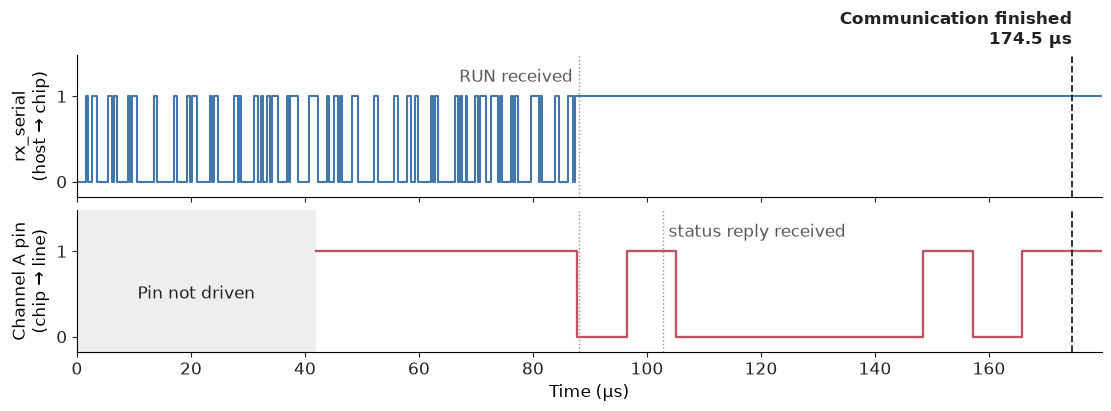

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def uart_end(sim, divider, nbits=8):
    # Cycle at which the last UART frame on channel A's pin ends. Its stop bit and the idle line
    # are both high, so no edge marks the end: count the bits from the frame's start bit instead.
    wave, end = sim["wave"], None
    for previous, current in zip(wave, wave[1:]):
        if previous[2] == 1 and current[2] == 0 and (end is None or current[0] >= end):
            end = current[0] + (nbits + 2) * divider
    return end


def plot_overview(sim, finished_cycle, cutoff_us=None):
    wave = list(sim["wave"])
    t0 = sim["start"]

    if not wave:
        raise ValueError("The waveform is empty.")

    def to_us(cycle):
        return (cycle - t0) * CLOCK_NS / 1000

    # Keep all samples; axis limits crop without distorting step boundaries.
    xs = [to_us(w[0]) for w in wave] + [to_us(sim["end"])]
    rx = [w[1] for w in wave]
    pin = [w[2] if w[2] in (0, 1) else float("nan") for w in wave]
    rx.append(rx[-1])
    pin.append(pin[-1])

    finished_us = to_us(finished_cycle)
    if cutoff_us is None:
        cutoff_us = finished_us * 1.03

    blue = "#4477AA"
    rose = "#BB5566"
    charcoal = "#222222"
    undriven_fill = "#EEEEEE"

    fig, axes = plt.subplots(
        2, 1, figsize=(11, 4),
        sharex=True, constrained_layout=True,
        facecolor="white"
    )

    axes[0].step(xs, rx, where="post", color=blue, linewidth=1.5)
    axes[1].step(xs, pin, where="post", color=rose, linewidth=1.7)

    # Undriven intervals remain distinct from both logic levels.
    undriven_spans = []
    for i, w in enumerate(wave):
        if w[2] == 2 and xs[i] < cutoff_us and xs[i + 1] > 0:
            axes[1].axvspan(
                max(0, xs[i]), min(cutoff_us, xs[i + 1]),
                facecolor=undriven_fill, edgecolor="none", zorder=0
            )
            undriven_spans.append(
                (max(0, xs[i]), min(cutoff_us, xs[i + 1]))
            )

    for ax in axes:
        ax.set_xlim(0, cutoff_us)
        ax.set_ylim(-0.18, 1.48)
        ax.set_yticks([0, 1])
        ax.tick_params(labelsize=12, colors=charcoal)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Subordinate marker for the final instruction byte.
        sent_us = to_us(sim["sent"])
        if 0 <= sent_us <= cutoff_us:
            ax.axvline(sent_us, color="#929292", linestyle=":",
                       linewidth=1, zorder=3)

        # Prominent completion marker across both panels.
        if 0 <= finished_us <= cutoff_us:
            ax.axvline(finished_us, color=charcoal,
                       linestyle="--", linewidth=1.3, zorder=4)

    if 0 <= sent_us <= cutoff_us:
        axes[0].text(
            sent_us - 1, 1.17, "RUN received",
            ha="right", fontsize=12, color="#595959"
        )

    visible_status = [
        to_us(at) for at in sim.get("status_at", [])
        if 0 <= to_us(at) <= cutoff_us
    ]
    for at in visible_status:
        axes[1].axvline(at, color="#929292", linestyle=":",
                       linewidth=1, zorder=3)
    if visible_status:
        axes[1].text(
            visible_status[0] + 1, 1.17, "status reply received",
            fontsize=12, color="#595959", zorder=5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1)
        )

    if 0 <= finished_us <= cutoff_us:
        axes[0].annotate(
            f"Communication finished\n{finished_us:.1f} µs",
            xy=(finished_us, 1.48), annotation_clip=False,
            xytext=(0, 4), textcoords="offset points",
            ha="right", va="bottom",
            fontsize=12, fontweight="bold", color=charcoal
        )

    axes[0].set_ylabel("rx_serial\n(host → chip)", fontsize=12)
    axes[1].set_ylabel("Channel A pin\n(chip → line)", fontsize=12)
    axes[1].set_xlabel("Time (µs)", fontsize=12)

    if undriven_spans:
        left, right = undriven_spans[0]
        for start, end in undriven_spans[1:]:
            if start > right:
                break
            right = max(right, end)

        axes[1].text(
            (left + right) / 2, 0.5, "Pin not driven",
            ha="center", va="center", fontsize=12, color=charcoal
        )

    return fig, axes


fig, axes = plot_overview(sim, uart_end(sim, ph.uart_divider(BAUD)))
# fig.savefig("communication_overview.pdf", bbox_inches="tight")
plt.show()

### 2.1 Zooming in on the frame

Now we read the pin back like a UART receiver would: find the falling edge of the start bit, then sample
the middle of each bit period. The bit period is the `CLOCK` divider from the program,
50 MHz / 115200 ≈ 434 clocks.

frame at 87.7 us: start=0 data=0b010000010(0x41) ('A') stop=1


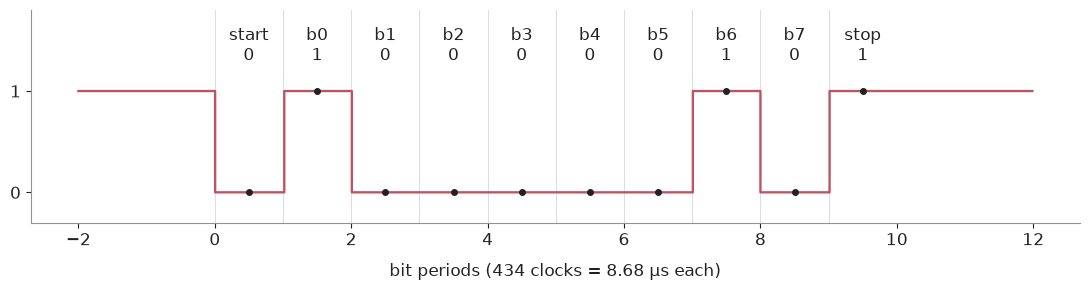

In [19]:
import bisect
import matplotlib.pyplot as plt

def level_at(wave, cycle, field):
    # Level of a signal (1 = rx_serial, 2 = data pin) at a given clock cycle
    i = bisect.bisect_right([w[0] for w in wave], cycle) - 1
    return wave[max(i, 0)][field]


def uart_frames(sim, divider, nbits=8):
    # Decode every UART frame on channel A's pin; return (start cycle, bit levels) per frame
    wave, frames = sim["wave"], []
    edges = [w[0] for i, w in enumerate(wave[1:], 1) if wave[i - 1][2] == 1 and w[2] == 0]
    for e in edges:
        if frames and e < frames[-1][0] + (nbits + 2) * divider:
            continue  # this edge is inside the previous frame
        bits = [level_at(wave, e + (k + 0.5) * divider, 2) for k in range(nbits + 2)]
        frames.append((e, bits))
    return frames


def plot_frame(sim, divider, start, bits):
    wave = sim["wave"]
    lo, hi = start - 2 * divider, start + 12 * divider
    cs = [c for c in range(lo, hi, max(1, divider // 40))]

    rose = "#BB5566"
    charcoal = "#222222"
    border = "#929292"

    fig, ax = plt.subplots(figsize=(11, 3), facecolor="white")
    ax.set_facecolor("white")

    ax.step(
        [(c - start) / divider for c in cs],
        [level_at(wave, c, 2) for c in cs],
        where="post", color=rose, linewidth=1.7
    )

    names = ["start"] + [f"b{k}" for k in range(len(bits) - 2)] + ["stop"]
    for k, (name, v) in enumerate(zip(names, bits)):
        ax.axvline(k, color="#DDDDDD", linewidth=0.8, zorder=0)
        ax.plot(k + 0.5, v, "o", color=charcoal, markersize=4, zorder=3)
        ax.text(
            k + 0.5, 1.25, f"{name}\n{v}",
            ha="center", va="bottom", fontsize=12, color=charcoal
        )

    ax.set_ylim(-0.3, 1.8)
    ax.set_yticks([0, 1])
    ax.set_xlabel(
        f"bit periods ({divider} clocks = {divider * CLOCK_NS / 1000:.2f} µs each)",
        fontsize=12, color=charcoal, labelpad=10
    )

    ax.tick_params(axis="both", labelsize=12, colors=charcoal)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(border)
        ax.spines[side].set_linewidth(0.8)

    fig.tight_layout()
    plt.show()


DIV = ph.uart_divider(BAUD)
for start, bits in uart_frames(sim, DIV):
    value = sum(b << k for k, b in enumerate(bits[1:9]))  # LSB first
    print(f"frame at {(start - sim['start']) * CLOCK_NS / 1000:.1f} us: start={bits[0]} "
          f"data=0b010000010(0x41) ({chr(value)!r}) stop={bits[9]}")
    plot_frame(sim, DIV, start, bits)

The dots are the sample points. Reading `b0` to `b7` gives `1000 0010`, least significant bit first,
which is `0x41`: the letter `A` we put in the `DATA` instruction.

### 2.2 A playground: give it a go!

Change the text or the baud rate and run the cell again. Up to four characters fit in the chip's host
FIFO before `RUN`; longer messages need the host to pace its `DATA` instructions (`HOST_FULL`).

90               CLEAR  ch=A
60               ORDER  ch=A  LSB first
A0 00 00         LINE   ch=A  code=NRZ, pin=0
B0 40 00 00 32   CLOCK  ch=A  ASYNC div=50 (~1 Mbit/s)
D0 E0            OUT    ch=A  push-pull always, idle=1
10 81 00 00      START  ch=A  write 1 bit, value=0x00, pin=0
30 40 00 09      MAIN   ch=A  write 9 bits, pin=0
C7 61            DATA   ch=A  8 bits, value=0x61
C0 01            DATA   ch=A  1 bit, value=0x01
C7 70            DATA   ch=A  8 bits, value=0x70
C0 01            DATA   ch=A  1 bit, value=0x01
C7 70            DATA   ch=A  8 bits, value=0x70
C0 01            DATA   ch=A  1 bit, value=0x01
70               RUN    ch=A  mode=RUN 

sent : b'app'
heard: b'app'
channel A: status 0x01 = complete
channel A: status 0x01 = complete
channel A: status 0x01 = complete


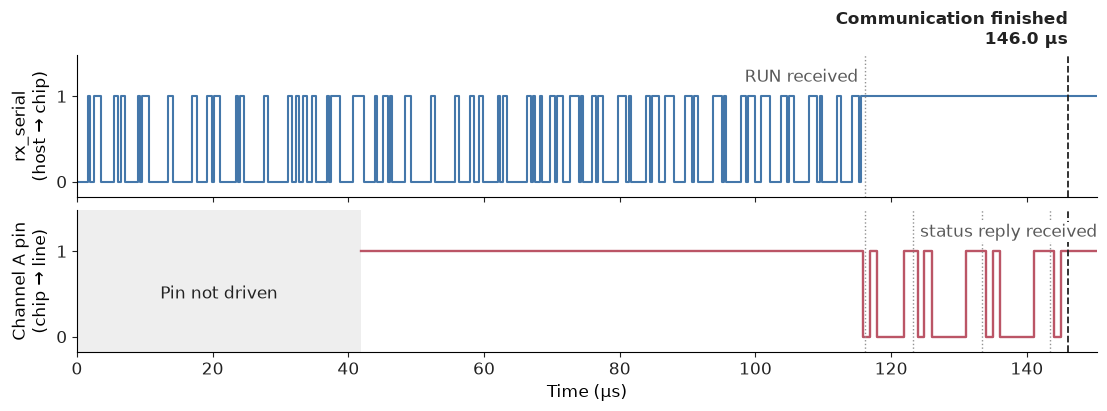

In [20]:
TEXT, BAUD2 = b"app", 1_000_000 # change either

prog2, rest2 = ph.uart_tx(0, BAUD2, TEXT)
assert not rest2, "keep the text to 4 characters or fewer for this demo"
print(dis.disassemble(prog2), "\n")

sim2 = run_on_chip(prog2, frames=len(TEXT))
DIV2 = ph.uart_divider(BAUD2)
heard = bytes(sum(b << k for k, b in enumerate(bits[1:9])) for _, bits in uart_frames(sim2, DIV2))
print("sent :", TEXT)
print("heard:", heard)
for ch, v in sim2["status"]:
    print(explain_status(ch, v))
fig, axes = plot_overview(sim2, uart_end(sim2, DIV2))
plt.show()

### 2.3 Solving tester's problem with hardware

The software tester at the start of this notebook put some bits on the line milliseconds late without
knowing it. ProEm sends the same kind of frame from a counter in hardware. The host only delivers
the program; once `RUN` arrives, every bit edge comes from the chip's clock, whatever the host is doing.
Here are four bytes from the simulated RTL, with every edge checked against the ideal bit grid:

In [21]:
text = b"ProE"
sim3 = run_on_chip(ph.uart_tx(0, BAUD, text)[0], frames=len(text))
wave3 = sim3["wave"]
edges = [c for i, (c, _, pin) in enumerate(wave3[1:], 1) if {pin, wave3[i - 1][2]} == {0, 1}]

worst, heard = 0, []
for start, bits in uart_frames(sim3, DIV):
    heard.append(sum(b << k for k, b in enumerate(bits[1:9])))
    for e in edges:
        if start <= e < start + 10 * DIV:
            off = (e - start) % DIV                 # distance from the nearest bit boundary
            worst = max(worst, min(off, DIV - off))

print("sent :", text)
print("heard:", bytes(heard))
print(f"edges checked: {len(edges)}, worst distance from the bit grid: {worst} clocks")
rate_error = 50e6 / DIV / BAUD - 1
print(f"bit period: {DIV} clocks = {DIV * CLOCK_NS / 1000:.3f} us for every bit "
      f"(ideal {1e6 / BAUD:.3f} us, {rate_error * 100:+.3f} %)")

sent : b'ProE'
heard: b'ProE'
edges checked: 26, worst distance from the bit grid: 0 clocks
bit period: 434 clocks = 8.680 us for every bit (ideal 8.681 us, +0.006 %)


Every edge sits exactly on the grid. The only error left is the divider's rounding: 434 clocks instead
of 434.03, the same for every bit and known in advance. A tester should be *exactly as wrong as you ask it
to be*. Because ProEm's error is exact, it can also be wrong on purpose: a `CLOCK` divider of 443 instead of
434 makes it a sender that is 2 % slow on every bit, to check how a DUT copes. With the software tester from the
beginning, the same 2 % would be hidden in its noise. Section 3.1 runs this experiment the other way round, with
ProEm as the receiver.

### 2.4 Inside the chip

Now let's take a look of what is happening inside the chip. Take the program from
section 1.4, which sends the letter `A`, and follow it from the instruction bytes to the pin:

| Step | Block | What happens to `A` |
|---|---|---|
| 1 | Control unit | `LINE`, `CLOCK`, `OUT`, `START` and `MAIN` set up the channel. The two `DATA` instructions queue 8 bits of `0x41` and 1 stop bit. |
| 2 | Host FIFO | Holds those two entries until `RUN` starts the frame. |
| 3 | `START` | Writes its single bit, the `0` of the start bit, as an entry in the frame buffer. |
| 4 | `MAIN` | Takes the two entries from the host FIFO and writes them to the frame buffer. |
| 5 | Entry dispatcher | Reads the buffer in order and passes each write entry to the encoder. |
| 6 | Line codec | Shifts the bits out with NRZ coding, one every 434 clocks, and drives the pin push-pull. |
| 7 | Return path | The frame's status follows the last entry through the buffer and goes back to the host. |

The three pieces below look at these blocks more closely.


#### The header chain

The first piece is the path a header field takes between the wires and the frame chain:

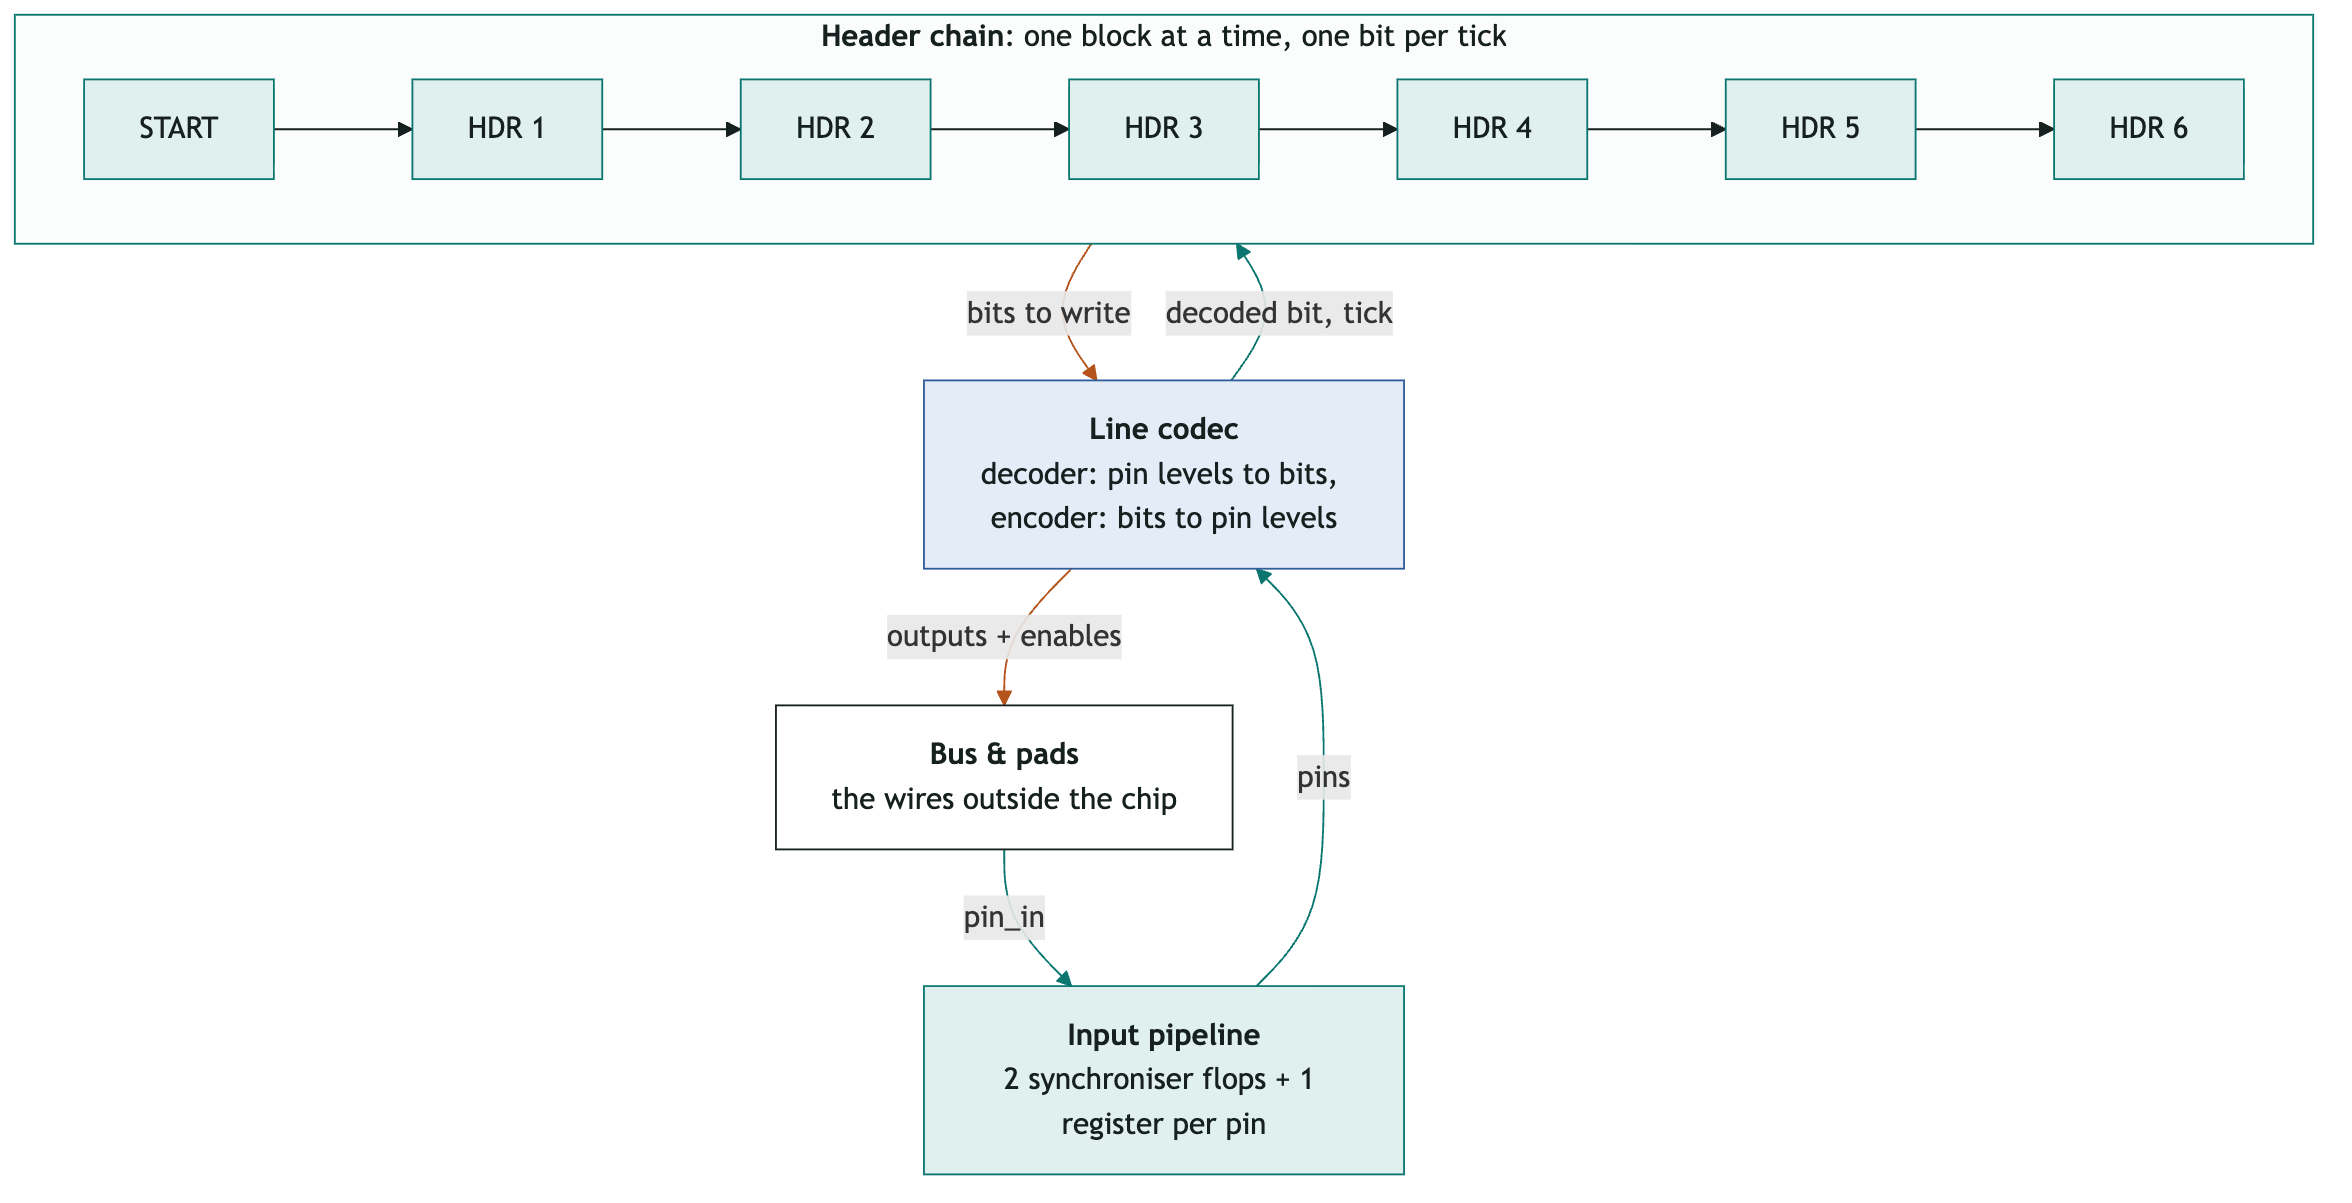

- **Bus and pads.** The wires outside the chip. Every pin's level enters on `pin_in`.
- **Input pipeline.** Two synchroniser flip-flops and one more register per pin make the outside signals
  safe to use inside the chip's 50 MHz clock domain.
- **Line codec.** The decoder turns pin levels into bits and produces the `tick` that says when a bit is
  valid. The encoder does the opposite for bits going out, and drives the outputs and their enables.
- **Header chain.** `START` and `HDR 1` to `HDR 6` run in order, and only one block is active at a time.
  Each header handles 1 to 8 bits: it compares them with an expected value, captures them, or writes them. Should there be a mismatch to the register, it will start over. After the last active header, the frame continues in `MAIN`.

To keep this piece simple, the diagram leaves out the blocks between the chain and the encoder: bits to
write first pass through the frame buffer and the entry dispatcher.


#### MAIN and the frame buffer

The second piece picks up where the header chain ends. `MAIN` handles the frame's data, and every field of
the frame, from a header or from `MAIN`, goes through the frame buffer as an **entry**:

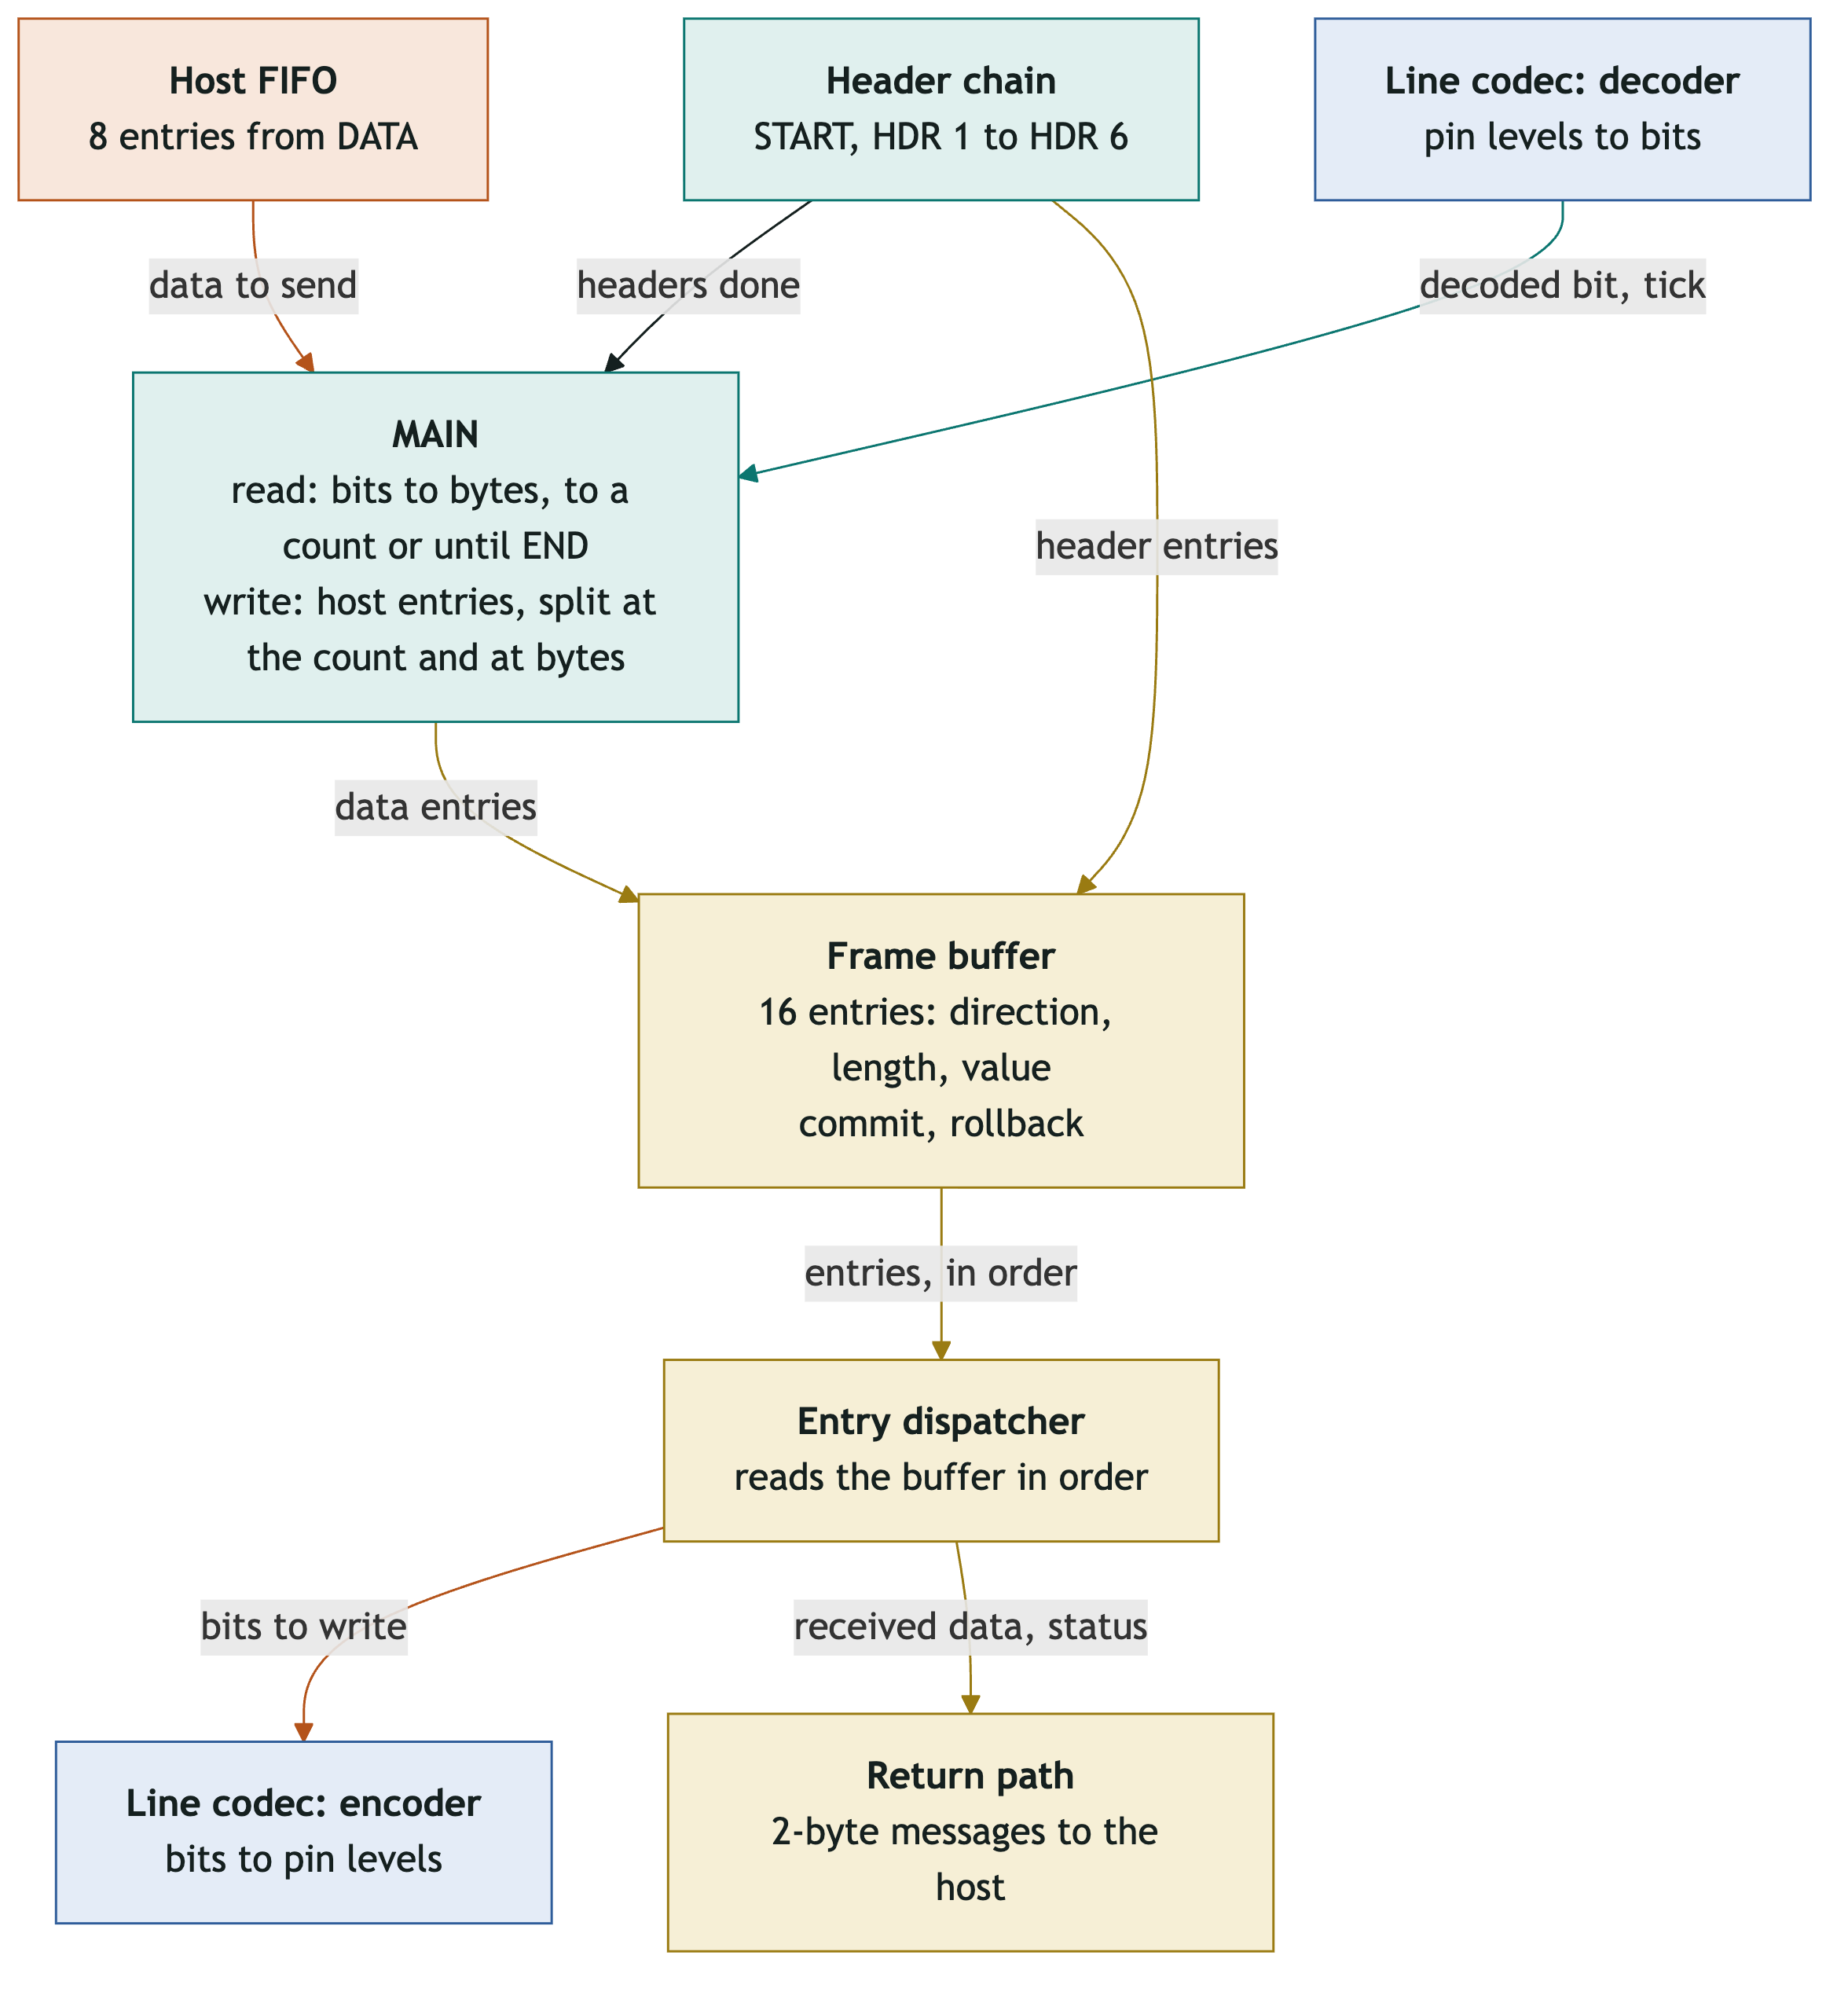

- **MAIN.** Runs after the last active header, for a programmed number of bits (a 16-bit count) or until `END`.
  When reading, it packs the decoded bits into bytes. When writing, it takes the host's `DATA` entries from
  the host FIFO and splits them at the count and at byte boundaries. It can also add an ACK slot after each
  byte, and its direction can be fixed or follow the run mode (`RUN READ` or `RUN WRITE`).
- **Frame buffer.** Holds 16 entries, each with a direction (write or not), a length and a value. It sits
  between the frame chain, which runs at the line's pace, and the blocks that consume its output.
- **Commit and rollback.** The dispatcher only sees *committed* entries. Bits to write and the status commit
  at once, while received header fields wait, at the latest until `MAIN` starts. If an ordinary abort or
  `HALT` comes first, a rollback discards whatever is still uncommitted, so the host never receives those
  fields. A branch abort commits them instead.
- **When the buffer fills up.** A write waits until there is room. Received data cannot wait, because the
  line keeps moving, so it is dropped and the frame's status reports an overflow.
- **Entry dispatcher.** Reads the buffer in order. An entry marked as a write goes to the encoder; any other
  entry, received data or the frame's status, goes to the return path and on to the host.

Because the status is just the last entry in the buffer, it leaves as soon as the last bits ahead of it have
been handed to the encoder. This is why the status reply in the waveform above arrives before the frame has left the pin.


#### The line codec

The third piece is the boundary between pin levels and bits. The frame chain only ever deals in plain bits
and ticks, so how a protocol looks on the wires (when bits happen, how they are coded and how the pins are
driven) is set here, by three instructions: `CLOCK`, `LINE` and `OUT`.

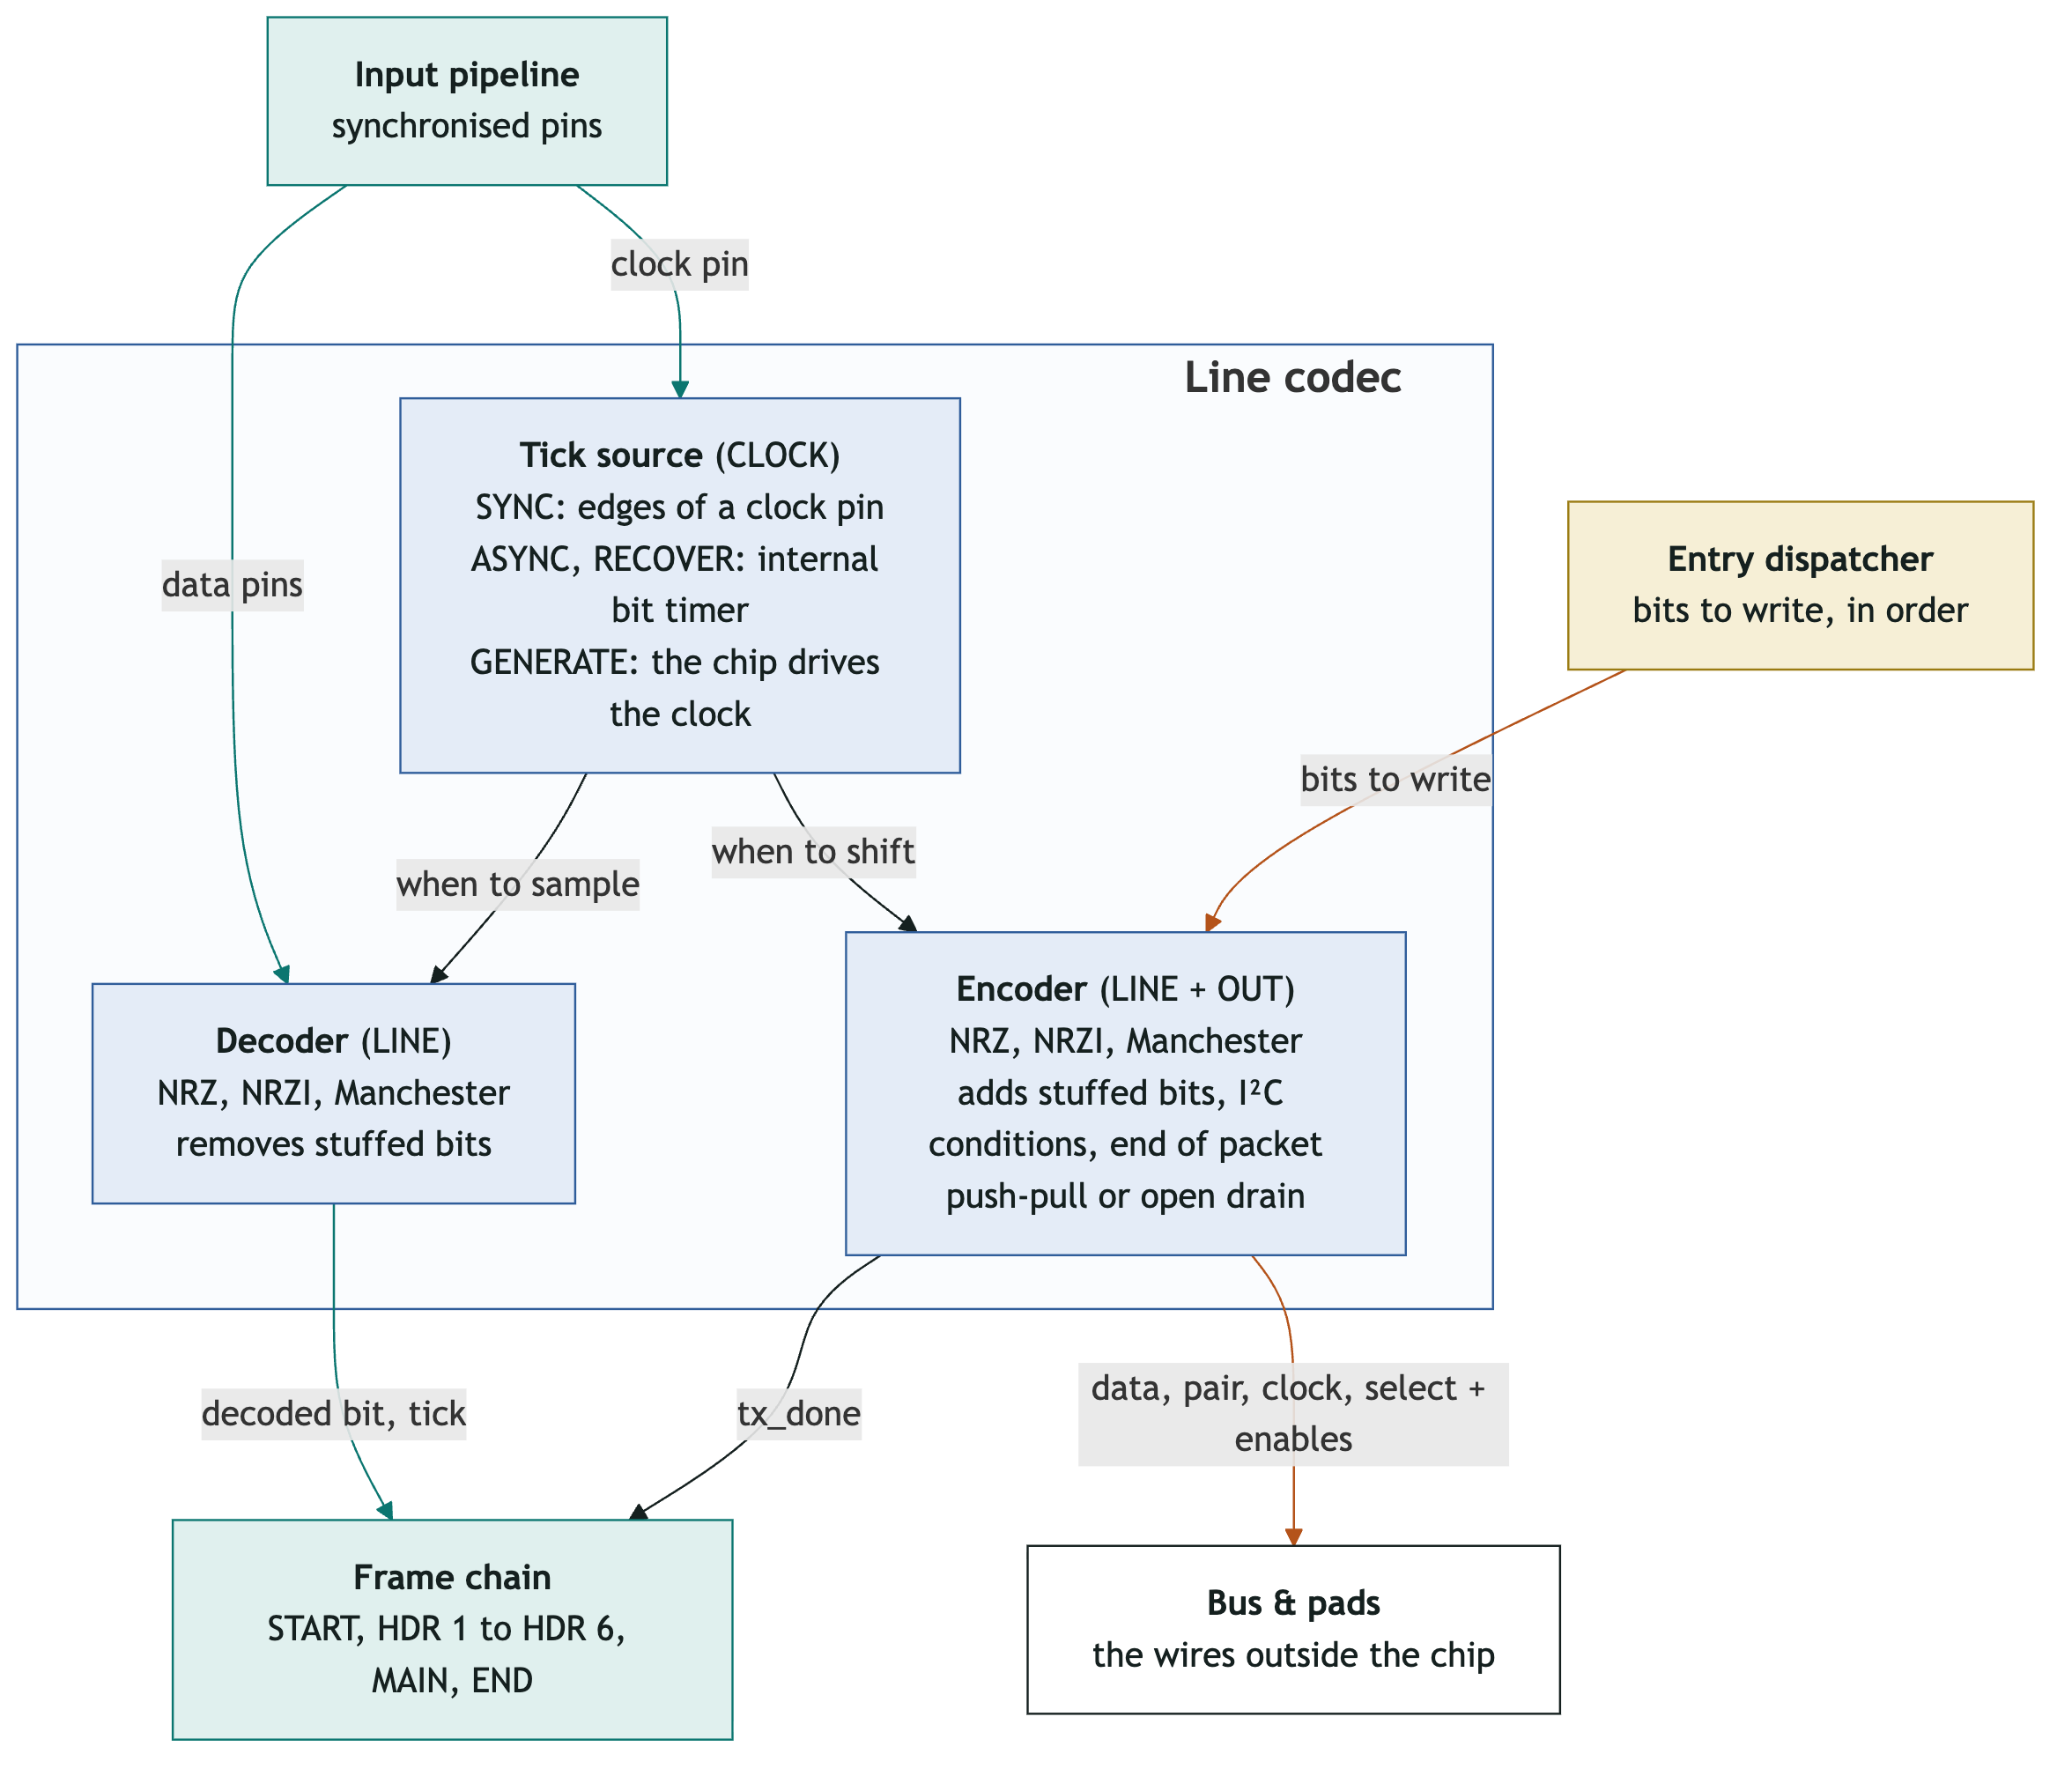

- **Tick source (`CLOCK`).** Decides when a bit happens. *SYNC* follows the edges of a clock pin. *ASYNC* and
  *RECOVER* use an internal bit timer of up to 22 bits, which re-centres on the data's own edges. *GENERATE*
  drives the clock from the chip; on an open-drain bus it waits while a device holds the clock low.
  This is the answer to the tester problem at the start of the notebook: bit timing comes from this hardware,
  not from software. A slow host can delay a frame or run out of data, but it cannot move a bit edge.
- **Decoder (`LINE`).** Turns pin levels into bits with the chosen line code, and drops the bits that the
  sender stuffed in. With a timed source, the decoded bit replaces the data pin in what the frame chain sees,
  and each good bit produces one `tick`. A stuffing error is reported to the chain.
- **Encoder (`LINE` + `OUT`).** Does the opposite, one entry at a time from the dispatcher, and pulses `tx_done`
  when an entry has gone out. It adds stuffed bits, the I²C START, repeated START and STOP conditions, and
  USB's end of packet. `OUT` selects how the pins are driven: not at all, only while sending, open drain,
  or always. The encoder also checks that the pin really carries the level it is driving, which is
  what makes arbitration possible.

This also answers a natural question: the chip has no idea what "UART" is. A protocol is a combination of
settings: these three for the wires, and the frame chain's blocks for the shape of the frame. The wire settings
of a few protocols, taken from the programs in this notebook and the project's tests:

| Protocol | Tick source | Line code | Output drive |
|---|---|---|---|
| UART | ASYNC | NRZ | push-pull |
| SPI controller | GENERATE | NRZ | push-pull |
| SPI target | SYNC | NRZ | push-pull |
| I²C controller | GENERATE | NRZ | open drain, with I²C conditions |
| USB low speed | RECOVER | NRZI on a pair, with stuffing | while sending, with end of packet |
| 10BASE-T receive | RECOVER | Manchester | none (receive only) |


## 3. Verification

ProEm is checked in several independent ways. Each one answers a different question:

| Check | Tool | Question it answers | Result |
|---|---|---|---|
| Pin-level tests: 16 programs, about 30 standards | Yosys CXXRTL + C++ device models | Does each protocol work against a model of a real device? | all pass |
| 2,400 random programs | CXXRTL | Do programs nobody wrote by hand also work? | all pass |
| Independent decoding of the waveforms | sigrok-cli protocol decoders | Does someone else's decoder agree that the waveforms are right? | all pass |
| Formal proofs of 6 modules | SymbiYosys | Is a property true for *every* input sequence, not just the tested ones? | all proven, unbounded |
| Line coverage | Verilator | Did the tests run every line of RTL? | 98.0 % (1344 of 1361) |
| Gate-level simulation | cocotb + Icarus Verilog | Does the synthesised netlist behave like the RTL? | pass |
| Lint | Verilator `-Wall` | Are there suspicious constructs? | clean, 13 reviewed waivers |

These results come from a full run of the repository's checks (`scripts/check_all.sh`) on Ubuntu 24.04,
which takes about a quarter of an hour. The cell below runs one of the project's tests, `t_uart`:
channel A receives from a sender whose clock is 2 % slow, while channel B transmits.

In [22]:
t0 = time.time()
subprocess.run(["g++", "-std=c++14", "-O1", "-I" + RUNTIME, "-Ibuild", "sim/t_uart.cpp", "-o", "build/t_uart"], 
               cwd=REPO_DIR, check=True)
print(subprocess.run(["build/t_uart", "16", "40.8"], cwd=REPO_DIR, check=True,
                     capture_output=True, text=True).stdout)
print(f"({time.time() - t0:.0f} s)")

  auto-baud locked                                       PASS
  UART RX on chain A: 5 bytes + stop bits                8:55 1:01 8:A3 1:01 8:00 1:01 8:FF 1:01 8:7E 1:01 | 01 01 01 01 01 (sender at 40.8 clocks/bit) PASS
  UART TX on chain B: "Hi!" on the line                  heard  48 69 21 PASS
  chain B: 3 frames complete                             01 01 01 PASS
ALL PASS

(8 s)


### 3.1 How far off can the host's clock be?

A pass or a fail says little about margins. `t_uart` takes the sender's bit period as an argument, so the
same test can be repeated while the sender's clock is made faster or slower. Channel A receives at
40 clocks per bit; the sender in the test bench uses anything from 36 to 44.5.

The receiver finds the falling edge of the start bit, then samples each bit in its middle and re-centres on
every edge. The worst case is a byte with no edges, such as `0x00`, which the test sends: the stop bit is
then sampled 9.5 bit periods after the start edge, at 9.5 × 40 = 380 clocks, with nothing to re-centre on.
That sample must land inside the sender's stop bit, which runs from 9 T to 10 T for a sender with T clocks
per bit. So the simple model predicts that the frame is received when 38 < T ≤ 42.2, about ±5 %.

received correctly for sender errors from -5.3 % to +5.3 %


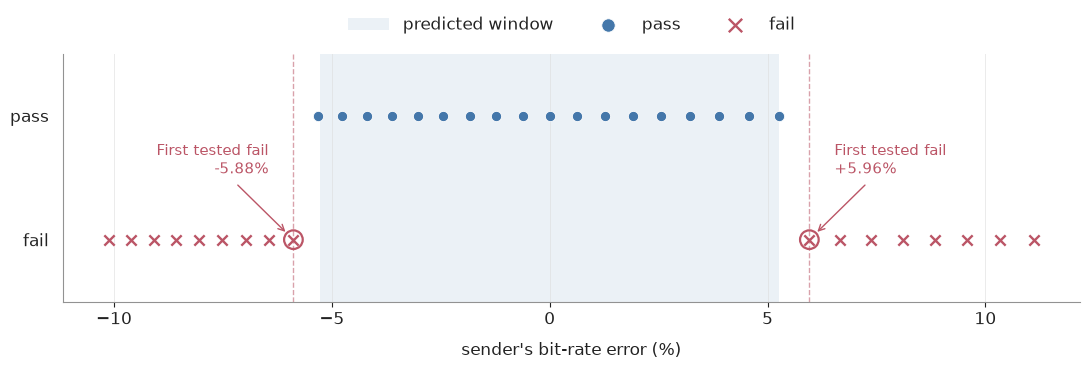

In [23]:
import matplotlib.pyplot as plt

R = 40                                         # channel A receives at 40 clocks per bit
senders = [36 + 0.25 * k for k in range(35)]   # the sender's clocks per bit, 36 to 44.5
passed = []
for T in senders:
    out = subprocess.run(["build/t_uart", "16", str(T)], cwd=REPO_DIR, capture_output=True, text=True).stdout
    passed.append("ALL PASS" in out)
errors = [(R / T - 1) * 100 for T in senders]  # sender's rate error in percent, positive = too fast

ok = [e for e, p in zip(errors, passed) if p]
print(f"received correctly for sender errors from {min(ok):+.1f} % to {max(ok):+.1f} %")

blue, rose = "#4477AA", "#BB5566"
charcoal, grey = "#222222", "#929292"

fig, ax = plt.subplots(figsize=(11, 3.8), facecolor="white")
ax.set_facecolor("white")

ax.axvspan(
    (R / (9.5 * R / 9) - 1) * 100,
    (R / (9.5 * R / 10) - 1) * 100,
    facecolor=blue, alpha=0.10, edgecolor="none",
    label="predicted window", zorder=0
)

ax.scatter(
    [e for e, p in zip(errors, passed) if p],
    [1] * len(ok),
    s=55, color=blue, edgecolors="white", linewidths=0.6,
    label="pass", zorder=3
)
ax.scatter(
    [e for e, p in zip(errors, passed) if not p],
    [0] * (len(passed) - len(ok)),
    s=55, color=rose, marker="x", linewidths=1.7,
    label="fail", zorder=3
)

# Find adjacent pass/fail transitions in increasing error order.
tested = sorted(zip(errors, passed))
first_failures = set()
for (e1, p1), (e2, p2) in zip(tested, tested[1:]):
    if p1 != p2:
        first_failures.add(e2 if p1 else e1)

# Highlight the failing sample beside each transition.
for error in sorted(first_failures):
    ax.axvline(
        error, color=rose, linestyle="--",
        linewidth=1, alpha=0.55, zorder=1
    )
    ax.scatter(
        [error], [0], s=180, facecolors="none",
        edgecolors=rose, linewidths=1.6, zorder=4
    )
    ax.annotate(
        f"First tested fail\n{error:+.2f}%",
        xy=(error, 0),
        xytext=(-18 if error < 0 else 18, 44),
        textcoords="offset points",
        ha="right" if error < 0 else "left",
        va="bottom", fontsize=11, color=rose,
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white", edgecolor="none", alpha=0.95
        ),
        arrowprops=dict(
            arrowstyle="->", color=rose,
            linewidth=1, shrinkB=8
        ),
        zorder=5
    )

ax.set_yticks([0, 1])
ax.set_yticklabels(["fail", "pass"])
ax.set_ylim(-0.5, 1.5)
ax.set_xlabel(
    "sender's bit-rate error (%)",
    fontsize=12, color=charcoal, labelpad=10
)

ax.tick_params(axis="both", labelsize=12, colors=charcoal)
ax.tick_params(axis="y", length=0, pad=10)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#DDDDDD", linewidth=0.7, alpha=0.6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(grey)
    ax.spines[side].set_linewidth(0.8)

legend = ax.legend(
    loc="lower center", bbox_to_anchor=(0.5, 1.02),
    ncol=3, frameon=False, fontsize=12,
    markerscale=1.3, handlelength=2.5, columnspacing=2
)
for label in legend.get_texts():
    label.set_color(charcoal)

fig.tight_layout()
plt.show()

The measured window, −5.3 % to +5.3 %, is the one the simple model predicts. UART links are usually
specified for a combined error of 2 to 3 %, so the receiver has room to spare; the test's own case, a
sender 2 % slow (40.8 clocks per bit), sits well inside it.

### 3.2 Proving instead of testing

A test checks the inputs someone thought of. A **formal proof** checks *every* input. `formal/uart_tx_formal.sv`
places a small reference model next to `uart_tx`: it records the byte when a transfer starts and works out
which bit the line should carry at every clock (`expected`): 0 for the start bit, the data bits LSB first,
then 1 for the stop bit. It then asserts, among other things, that `tx_serial == expected` at every clock.
The bit period (`ratio`, 1 to 15 clocks), the data and the moment `tx_valid` rises are all left free, so the
solver may choose any of them.

The repository proves this with no depth limit, using the `abc pdr` engine. That engine is not part of the
`pip` packages, so here the same property is checked as a **bounded proof** with the Z3 solver: no input
sequence of up to 40 clocks can break it. This takes about a minute.

In [24]:
%pip install -q --disable-pip-version-check z3-solver==5.3.2.0

Note: you may need to restart the kernel to use updated packages.


In [25]:
FORMAL = os.path.join(REPO_DIR, "build/formal")
os.makedirs(FORMAL, exist_ok=True)

def prove_uart_tx(rtl_file, name, depth=40):
    # Bounded proof of a uart_tx source file against formal/uart_tx_formal.sv.
    # Returns (passed, summary lines, counterexample trace or None).
    with open(os.path.join(FORMAL, name + ".sby"), "w") as f:
        f.write(f"[options]\nmode bmc\ndepth {depth}\n\n"
                "[engines]\nsmtbmc z3\n\n"
                "[script]\nread -formal uart_tx.sv uart_tx_formal.sv\nprep -top uart_tx_formal\nmemory_map\n\n"
                f"[files]\nuart_tx.sv {rtl_file}\n"
                f"uart_tx_formal.sv {os.path.join(REPO_DIR, 'formal/uart_tx_formal.sv')}\n")
    run = subprocess.run(["yowasp-sby", "-f", "--yosys", "yowasp-yosys", "--smtbmc", "yowasp-yosys-smtbmc",
                          "--witness", "yowasp-yosys-witness", name + ".sby"],
                         cwd=FORMAL, capture_output=True, text=True)
    summary = [l.split("summary: ", 1)[1] for l in run.stdout.splitlines()
               if "summary: " in l and "Elapsed" not in l]
    trace = os.path.join(FORMAL, name, "engine_0", "trace.vcd")
    return run.returncode == 0, summary, trace if os.path.exists(trace) else None

t0 = time.time()
passed, summary, _ = prove_uart_tx(os.path.join(REPO_DIR, "src/primitives/uart_tx.sv"), "uart_tx")
print("\n".join(summary))
print(f"uart_tx: {'PASS, no counterexample within 40 clocks' if passed else 'FAIL'} ({time.time() - t0:.0f} s)")

engine_0 (smtbmc z3) returned pass
engine_0 did not produce any traces
uart_tx: PASS, no counterexample within 40 clocks (68 s)


Now a deliberate bug. In the `SEND` state, `uart_tx` puts `shiftReg[1]` on the line while it shifts the
register right: with non-blocking assignments the shift only happens at the clock edge, so the next bit is
still one place to the left. Using `shiftReg[0]` instead looks just as reasonable. The change is made in a copy under `build/formal/`;
the chip's RTL in `src/` is not touched:

In [26]:
good = open(os.path.join(REPO_DIR, "src/primitives/uart_tx.sv")).read()
assert good.count("internal_serial <= shiftReg[1];") == 1
buggy_file = os.path.join(FORMAL, "uart_tx_bug.sv")
with open(buggy_file, "w") as f:
    f.write(good.replace("internal_serial <= shiftReg[1];", "internal_serial <= shiftReg[0];"))

t0 = time.time()
passed, summary, trace = prove_uart_tx(buggy_file, "uart_tx_bug")
print("\n".join(summary))
print(f"buggy uart_tx: {'PASS' if passed else 'FAIL, counterexample found'} ({time.time() - t0:.0f} s)")
assert not passed and trace, "the proof should have found the bug"

engine_0 (smtbmc z3) returned FAIL
counterexample trace: uart_tx_bug/engine_0/trace.vcd
  failed assertion uart_tx_formal._witness_.check_assert_uart_tx_formal_sv_94_25 at uart_tx_formal.sv:94.4-94.34 step 4
buggy uart_tx: FAIL, counterexample found (4 s)


The solver answers in about a second with a **counterexample**: a concrete input sequence, written as a
waveform, for which the assertion fails. Plotting it shows exactly what went wrong:

byte sent: 0x02 = 00000010, bit period: 1 clock(s); first wrong bit at step 4


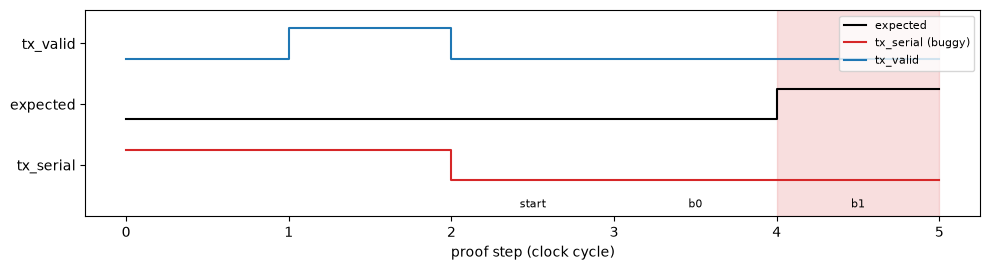

In [27]:
def read_vcd(path, names):
    # Values of the harness's own signals at each proof step of a SymbiYosys trace
    ids, scope, step_id, state, steps = {}, [], None, {}, {}
    for line in open(path):
        tok = line.split()
        if not tok:
            continue
        if tok[0] == "$scope":
            scope.append(tok[2])
        elif tok[0] == "$upscope":
            scope.pop()
        elif tok[0] == "$var":
            if tok[4] == "smt_step":
                step_id = tok[3]
            elif scope == ["uart_tx_formal"] and tok[4] in names:
                ids[tok[3]] = tok[4]
        elif tok[0].startswith("#") and "step" in state:
            steps[state["step"]] = dict(state)
        elif tok[0].startswith("b") and len(tok) == 2:
            if tok[1] == step_id:
                state["step"] = int(tok[0][1:], 2)
            elif tok[1] in ids:
                state[ids[tok[1]]] = int(tok[0][1:], 2)
    steps[state["step"]] = dict(state)
    return [steps[k] for k in sorted(steps)]

trace_steps = read_vcd(trace, {"tx_valid", "tx_serial", "expected", "active", "bitNum", "sent", "ratio"})
fail_step = next(s["step"] for s in trace_steps if s["active"] and s["tx_serial"] != s["expected"])
trace_steps = [s for s in trace_steps if s["step"] <= fail_step]  # the trace stops being meaningful there
print(f"byte sent: 0x{trace_steps[-1]['sent']:02X} = {trace_steps[-1]['sent']:08b}, "
      f"bit period: {trace_steps[-1]['ratio']} clock(s); first wrong bit at step {fail_step}")

xs = [s["step"] for s in trace_steps] + [trace_steps[-1]["step"] + 1]  # one more x so the last step is drawn
line = lambda name, offset: [s[name] + offset for s in trace_steps] + [trace_steps[-1][name] + offset]
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.step(xs, line("expected", 2), where="post", color="black", label="expected")
ax.step(xs, line("tx_serial", 0), where="post", color="tab:red", label="tx_serial (buggy)")
ax.step(xs, line("tx_valid", 4), where="post", color="tab:blue", label="tx_valid")
for s in trace_steps:
    if s["active"]:
        name = "start" if s["bitNum"] == 0 else "stop" if s["bitNum"] == 9 else f"b{s['bitNum'] - 1}"
        ax.text(s["step"] + 0.5, -0.9, name, ha="center", fontsize=8)
ax.axvspan(fail_step, fail_step + 1, color="tab:red", alpha=0.15)
ax.set_yticks([0.5, 2.5, 4.5], ["tx_serial", "expected", "tx_valid"])
ax.set_ylim(-1.2, 5.6)
ax.set_xlabel("proof step (clock cycle)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In the shaded step the reference model expects the next data bit, but the buggy transmitter repeats the
one it already sent. The pin-level tests would also have caught this, but only for the bytes and bit periods
they happen to use; the proof needs no test vectors, and its counterexample is the shortest one there is.

### 3.3 Random programs

The project's `t_random` and `t_random_branch` run 2,400 random programs between them. The same idea fits in a few lines with the tools from
sections 1 and 2: pick a random text and baud rate, build the program with `proem_host`, run it on the RTL,
decode the pin and compare. Each run exercises the host library, the chip and the decoder together.

In [28]:
import random, string

random.seed(2027)  # fixed, so every run of the notebook tests the same cases
t0 = time.time()
for case in range(12):
    text = "".join(random.choice(string.ascii_letters + string.digits + string.punctuation)
                   for _ in range(random.randint(1, 4))).encode()
    baud = random.choice([115_200, 230_400, 460_800, 921_600])
    prog, rest = ph.uart_tx(0, baud, text)
    divider = ph.uart_divider(baud)
    result = run_on_chip(prog, frames=len(text), quiet=12 * divider)
    heard = bytes(sum(b << k for k, b in enumerate(bits[1:9])) for _, bits in uart_frames(result, divider))
    statuses = [v for _, v in result["status"]]
    assert heard == text and statuses == [0x01] * len(text), (text, baud, heard, statuses)
    print(f"case {case:2}: {baud:>7} baud  sent {text!r:<8} heard {heard!r:<8} ok")
print(f"12 random cases passed ({time.time() - t0:.0f} s)")

case  0:  115200 baud  sent b'7'     heard b'7'     ok
case  1:  460800 baud  sent b'@'     heard b'@'     ok
case  2:  460800 baud  sent b'=xZx'  heard b'=xZx'  ok
case  3:  115200 baud  sent b'JK'    heard b'JK'    ok
case  4:  460800 baud  sent b'MiG'   heard b'MiG'   ok
case  5:  460800 baud  sent b'#Du~'  heard b'#Du~'  ok
case  6:  921600 baud  sent b'CY6'   heard b'CY6'   ok
case  7:  460800 baud  sent b'7V'    heard b'7V'    ok
case  8:  115200 baud  sent b'y'     heard b'y'     ok
case  9:  115200 baud  sent b'8H&'   heard b'8H&'   ok
case 10:  115200 baud  sent b'1X+'   heard b'1X+'   ok
case 11:  115200 baud  sent b'I.'    heard b'I.'    ok
12 random cases passed (1 s)


### 3.4 Testing the host software

The disassembler from section 1 is software and needs its own tests. Two kinds are cheap: a **round trip**
(build instructions with `proem_host` from random arguments, decode them with `proem_disasm`, and check that
the arguments come back) and **fuzzing** (feed every possible header byte with random operands and check
that the decoder never crashes).

In [29]:
random.seed(1)
checked = 0
for _ in range(500):
    n, cyc, val = random.randint(1, 6), random.randint(1, 8), random.randrange(256)
    w, grp, sr = random.randrange(2), random.randrange(3), random.randrange(2)
    text = dis.decode(bytes(ph.hdr(0, n, val, cyc, 0, w, grp=grp, sr=sr)))
    assert f"#{n} " in text and f"{cyc} bit" in text and f"value=0x{val:02X}" in text, text
    assert ("write" if w else "read") in text and ("always", "read runs", "write runs")[grp] in text, text
    assert (", Sr" in text) == bool(sr), text

    div = random.randrange(1, 1 << 22)
    text = dis.decode(bytes(ph.clock(0, ph.ASYNC, div)))
    assert f"div={div} " in text, text

    width = random.randint(1, 16)
    poly = random.randrange(1 << width)
    text = dis.decode(bytes(ph.crc_a(0, width, poly)))
    assert f"CRC-{width} " in text and int(text.split("poly=")[1].split(",")[0], 16) == poly, text
    checked += 3
print(f"round trip: {checked} instructions built by proem_host and decoded back correctly")

for header in range(256):
    for _ in range(50):
        dis.decode(bytes([header] + [random.randrange(256) for _ in range(dis.OPERANDS[header >> 4])]))
print("fuzzing: 256 header bytes x 50 random operand sets decoded without an error")

round trip: 1500 instructions built by proem_host and decoded back correctly
fuzzing: 256 header bytes x 50 random operand sets decoded without an error


### 3.5 What the checks found

Verification is only useful if it finds problems. Two bugs in the RTL were found this way and fixed before
the layout was made (details in `docs/verification_report.pdf`):

- **A lost `tx_done` after a cancel**, found by the formal proof of the line codec. If a frame was aborted
  twice within two clocks, the codec could lose one of its "bit sent" pulses. The frame chain would then
  wait forever for a bit that had already gone, and the channel would stop receiving. The unfixed RTL
  fails the proof in 8 steps; the fixed RTL passes it with no depth limit.
- **No hold time in SPI modes 1 and 3**, found because coverage showed a code path no test had run. The
  chip changed MOSI on the same clock edge on which the device samples it. A new test with all four SPI
  modes reproduced it (`A55A` came back as `4AB4`), and the fix keeps the data stable for half a clock
  period on either side of the sampling edge.

Running the suite for this notebook turned up one more bug and one behaviour worth knowing:

- **A test-bench bug that only shows on ARM.** On an ARM64 Linux machine `t_standards` crashed. One test
  left behind a callback that still referred to its own local variables; the next test called it after
  those variables were gone. This is undefined behaviour in C++: on the x86-64 machines the project's CI
  uses it happened to do no harm, which is why it had not been seen. The fix resets the callback at the
  start of `reset_both()` instead of at the end (commit `1d6649a`). The chip's RTL is not affected.
- **The status byte comes before the frame has left the pin.** This is by design (section 2): the status
  is queued behind the frame's bits and leaves once its last bits have been handed to the line codec,
  which still has to shift them out at the line's bit rate. It is not a bug, but a host should not read
  "complete" as "the line is now idle".
  The UART frame from section 2 shows the size of the gap:

In [30]:
frame_start = uart_frames(sim, DIV)[0][0]
frame_end = frame_start + 10 * DIV  # start bit, 8 data bits, stop bit
print(f"frame on the pin : {us(frame_start):6.1f} us to {us(frame_end):6.1f} us")
print(f"status received  : {us(sim['status_at'][0]):6.1f} us")

frame on the pin :   87.7 us to  174.5 us
status received  :  102.8 us


## 4. From RTL to silicon

The RTL describes registers and what happens to them on each clock. Three steps turn it into a chip:

1. **Synthesis** (Yosys) turns the RTL into logic gates and flip-flops.
2. **Place and route** (LibreLane) places every cell on the die and draws the metal wires between them,
   then checks timing, design rules (DRC) and that the layout matches the netlist (LVS).
3. The result, a **GDS** file, goes to the foundry. Tiny Tapeout combines many small designs on one die
   to share the cost.

Synthesis is quick enough to run here. This is the UART transmitter that sends the chip's replies back
to the host (`src/primitives/uart_tx.sv`, about 100 lines), the same module as in section 3.2:

In [31]:
subprocess.run(["yowasp-yosys", "-q", "-p",
                "read_verilog -sv src/primitives/uart_tx.sv; synth -top uart_tx; "
                "tee -q -o build/uart_tx_stat.txt stat"],
               cwd=REPO_DIR, check=True)

cells = {}
for line in open(os.path.join(REPO_DIR, "build/uart_tx_stat.txt")):
    parts = line.split()
    if len(parts) == 2 and parts[1].startswith("$_"):
        cells[parts[1]] = int(parts[0])

flip_flops = sum(n for name, n in cells.items() if "DFF" in name)
total = sum(cells.values())
print(f"uart_tx: {total} cells = {flip_flops} flip-flops + {total - flip_flops} logic gates\n")
for name, n in sorted(cells.items(), key=lambda kv: -kv[1]):
    print(f"{n:5}  {name}")

uart_tx: 194 cells = 32 flip-flops + 162 logic gates

   54  $_AND_
   28  $_XOR_
   21  $_ANDNOT_
   19  $_DFF_PN0_
   16  $_XNOR_
   11  $_DFFE_PN0P_
   11  $_NAND_
   11  $_OR_
   10  $_MUX_
    8  $_NOT_
    2  $_NOR_
    1  $_DFFE_PN1P_
    1  $_DFF_PN1_
    1  $_ORNOT_


The logic gates are the ones built by hand in the first chapters of *nand2tetris*: `$_AND_`, `$_NAND_`,
`$_OR_`, `$_XOR_`, `$_NOT_`, `$_MUX_`, plus combined forms such as `$_ANDNOT_` (A and not B). The
flip-flops are the registers declared in the RTL: the 8-bit shift register, the 16-bit bit-period counter,
the 3-bit bit index, the output bit and the state. That is 30 bits, but Yosys finds 32 flip-flops,
because it re-encodes the 4-state machine *one-hot* (one flip-flop per state) instead of 2 bits.
`$_DFF_PN0_` is a D flip-flop on the rising clock edge (`P`) with an active-low reset (`N`) to 0;
`$_DFFE_…` adds an enable.

The whole chip is too large to place and route in a notebook. It was hardened with the same flow as
Tiny Tapeout's GitHub workflow for IHP SG13CMOS5L:

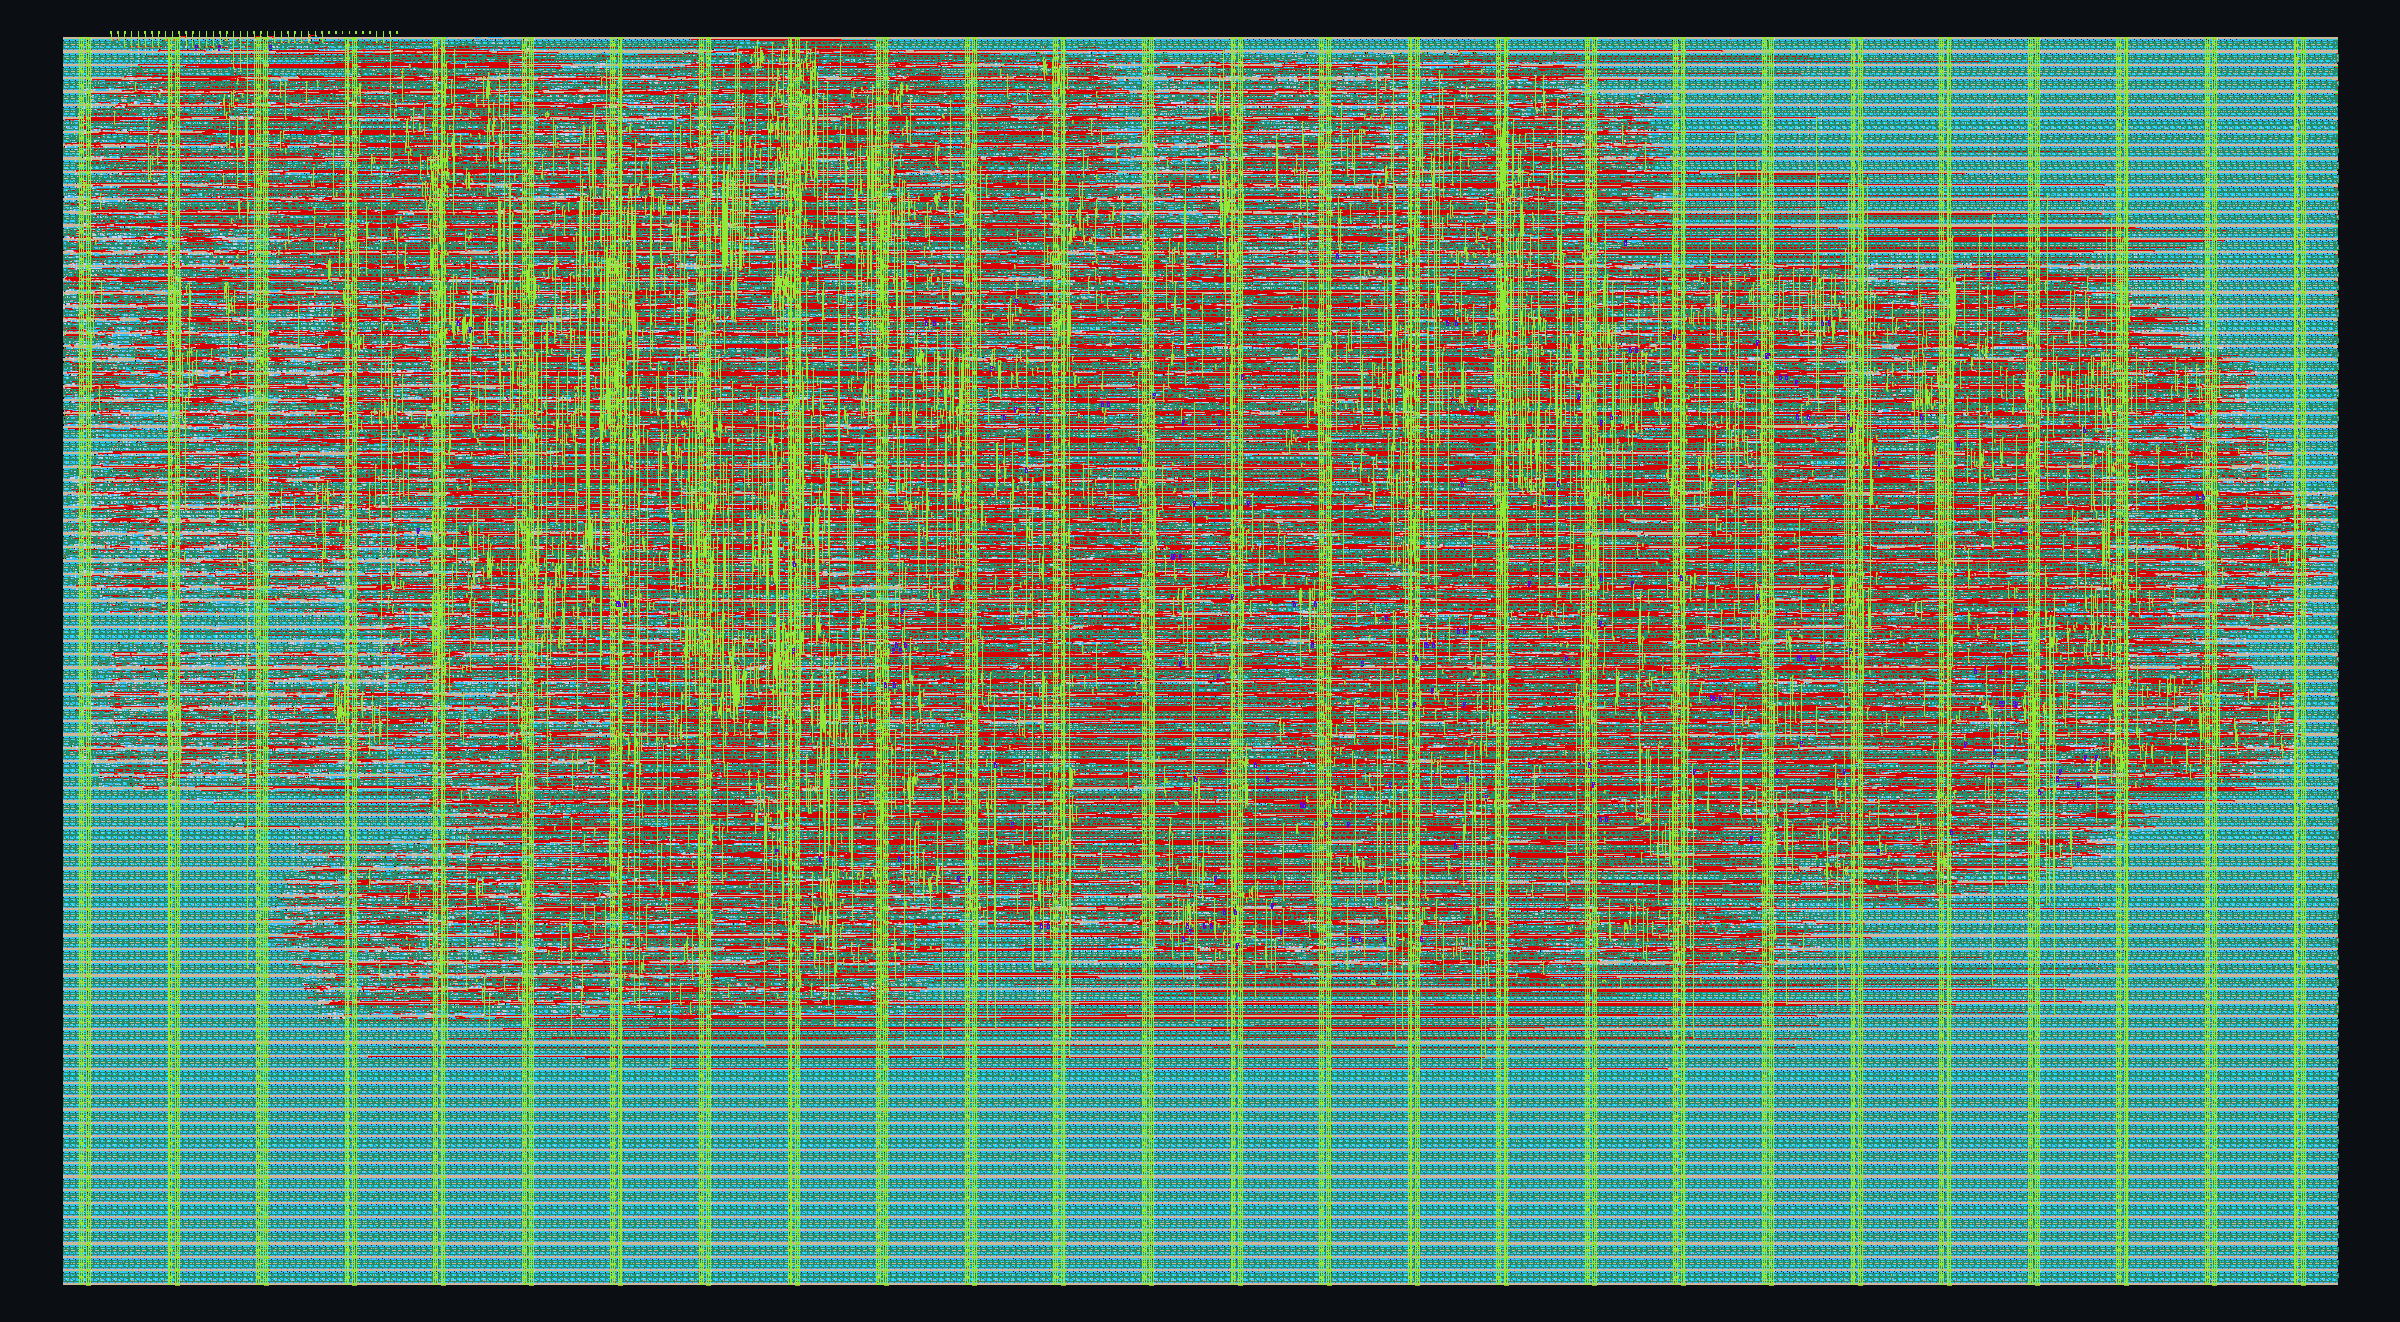

In [32]:
from IPython.display import Image, display
display(Image(os.path.join(REPO_DIR, "gds/images/layout_full.png"), width=900))

| | |
|---|---|
| Process | IHP SG13CMOS5L 130 nm (Metal1 to Metal4 plus TopMetal1) |
| Size | 6 × 4 Tiny Tapeout tiles, 1289.28 × 710.64 µm |
| Cells | 18,969 after synthesis; 25,612 after place and route (including 6,104 timing repair buffers and 362 clock tree cells) |
| Utilisation | 43 % of the core area |
| Timing at 50 MHz | met at every corner: setup slack 9.8 ns typical, 3.8 ns at the slow corner (1.08 V, 125 °C) |
| Maximum clock | 98 MHz typical, 62 MHz at the slow corner |
| Power | about 10.2 mW at 50 MHz (8.1 to 12.7 mW across corners) |
| Sign-off | Magic DRC 0 errors, LVS clean, 0 routing and antenna violations; gate-level tests pass on the routed netlist |

The full-chip cell count differs from the small example above because the layout uses IHP's standard
cells rather than Yosys's generic gates. `gds/README.md` in the repository has the details.

## 5. Limitations and future work

**Known limits** (from the design reference):

- **Return link bandwidth.** Every received entry costs two bytes on the return UART. At 4 clocks per bit
  it keeps up with USB low speed and the clocked standards, but full-size 10BASE-T frames arrive faster:
  they are received, overflow the 16-entry frame buffer, and are reported with the overflow flag.
- **Feeding fixed-timing lines.** Each `DATA` entry costs 140 clocks on the instruction link, so a UART
  transmit keeps up to about 1.2 Mbaud. Faster fixed-timing lines must be preloaded (8 entries) or end
  with an underrun.
- **Head-of-line blocking.** A received entry waiting for the return link holds up the written bits behind
  it. I²C simply stretches the clock; a timed transmit would pause.
- **Not supported yet:** clock stretching as an I²C target, a loop action for `BRANCH`, and a CRC reply gap
  on Manchester lines.

**Future work:** helpers in the host library for SPI, I²C and the other standards (today only UART has
one), a `BRANCH` loop action to repeat a block without the host, and formal proofs for the remaining
modules.

## References

**This project**
- ProEm repository: `README.md`, the ISA reference (`docs/protocol_emulator_isa.pdf`), the design reference
  (`docs/protocol_emulator_design.pdf`) and the verification report (`docs/verification_report.pdf`).

**Tools used in this notebook**
- Yosys and CXXRTL: https://github.com/YosysHQ/yosys
- YoWASP, Yosys for `pip`: https://yowasp.org
- SymbiYosys: https://github.com/YosysHQ/sby
- Z3 theorem prover: https://github.com/Z3Prover/z3
- matplotlib: https://matplotlib.org

**Tools used by the project's full checks and the layout**
- Verilator: https://www.veripool.org/verilator
- cocotb: https://www.cocotb.org
- Icarus Verilog: https://github.com/steveicarus/iverilog
- sigrok: https://sigrok.org
- LibreLane: https://github.com/librelane/librelane
- Tiny Tapeout: https://tinytapeout.com
- IHP Open PDK: https://github.com/IHP-GmbH/IHP-Open-PDK